# 68. Matched checkpoint comparison: `002.27 best` vs `003.4 last`

**Purpose.** Compare the original 6D rotation-head checkpoint against the later 3D rotation-vector checkpoint using exactly the same KAIST physical windows and injected rotation faults. **No training or checkpoint modification.**

The source notebooks show that these are **different output-head architectures**, despite an equivalent Transformer/pooler configuration:
- `002.27 best` uses `PooledCalibration6DModel` and predicts an SO(3) correction matrix `delta_rotation`.
- `003.4 last` uses `PooledCalibrationModel` and predicts a 3D rotation vector `delta_xi[:, :3]`.

We convert *both* outputs to SO(3) correction matrices and evaluate the identical physical metric:

\[
R_{\rm after} = \widehat{\Delta R}\,R_{\rm before},\qquad
\theta_{\rm residual} = d_{SO(3)}(R_{\rm after},R_{\rm truth}).
\]

**What this notebook produces**
1. One-step residual vs initial error, required-vs-predicted magnitude, signed axis cosine, improvement fraction, **one separate figure for each sensor × X/Y/Z/U1**.
2. 12-window *chronological feedback* rollouts from exact initial faults, **one separate figure for each sensor × X/Y/Z/U1**, with final-residual curves and trajectories for 0°, 30°, 90°, 150°, 179°.
3. Case-matched differences (`003.4 minus 002.27`), win fractions, mean/median/p90, fixed-point drift, summary heatmaps and CSV exports.

The default split is **validation (Urban26, Urban28)**, so comparisons do not contaminate the held-out test set. Changing `EVAL_SPLIT` to `'test'` makes a deliberate final test-set comparison.

## 1. Repository imports and exact model APIs

In [1]:
from pathlib import Path
from dataclasses import replace
import json
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from IPython.display import display

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / 'src' / 'obscalib').is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError('Run this notebook inside nn-obs-calib or one of its subdirectories.')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs
from obscalib.augmentations.config import (AugmentationConfig, CalibrationEventConfig, CommonBodyFrameRandomizationConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, SensorTopologyAugmentationConfig, TrueCalibrationAugmentationConfig)
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.calibration.state import CalibrationState
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import SensorStreamBatch, WindowBatch
from obscalib.geometry.lie import so3_exp, so3_log
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_6d_model import PooledCalibration6DModel
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint

print('Repository:', ROOT, '| PyTorch:', torch.__version__, '| CUDA:', torch.cuda.is_available())

Repository: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib | PyTorch: 2.7.1+cu126 | CUDA: True


## 2. All configurable evaluation settings

In [3]:
CHECKPOINTS = {
    '002.27 best': ROOT / 'runs' / 'kaist_pooled_calibration_6d_002.27_full_rotation_regression' / 'best.pt',
    '003.4 last': ROOT / 'runs' / 'kaist_large_paired_003.4_4step_rollout' / 'last.pt',
}
MODEL_ORDER = tuple(CHECKPOINTS)
COLORS = {'002.27 best': '#2563eb', '003.4 last': '#ea580c'}

EVAL_SPLIT = 'validation'  # 'validation' or 'test'
EVAL_SEQUENCES = {'validation': ('Urban26', 'Urban28'), 'test': ('Urban38', 'Urban39')}[EVAL_SPLIT]
KAIST_DATASET_ROOT = Path('/mnt/d/Downloads/MobRobLab/KAISTDataset')
LIDAR_POSE_ROOT = Path('/home/camel/Skoltech/phd_proposal/data/KAISTDataset')
OUTPUT_DIR = ROOT / 'runs' / 'checkpoint_comparison_00227_best_vs_0034_last' / EVAL_SPLIT

RANDOM_SEED = 12345
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODEL_DTYPE = torch.float32

# PyTorch NestedTensor eval fastpath can fail on variable-length sensor token batches.
DISABLE_MHA_FASTPATH = True
if DISABLE_MHA_FASTPATH and hasattr(torch.backends, 'mha'):
    torch.backends.mha.set_fastpath_enabled(False)
CALIBRATION_KEYS = ('imu', 'lidar', 'lidar_right')
WINDOW_DURATION_S, WINDOW_STRIDE_S, MAX_SAMPLES_PER_SENSOR = 5.0, 5.0, 700

ANGLES_DEG = (0., 15., 30., 60., 90., 120., 150., 175., 179.)
AXIS_NAMES = ('X', 'Y', 'Z', 'U1')
AXIS_SEED = 650_272  # Retains the earlier DIAG65 U1 axis.
FAULT_KEYS = CALIBRATION_KEYS

# Physical truth is re-expressed identically for both models. The source notebooks
# used arbitrary true 3D orientations. No artificial measurement noise is added.
TRUE_CALIBRATION_ROTATION_MAX_DEG = 180.0
TRUE_CALIBRATION_TAU_MAX_S = 0.030  # Set 0.0 for a no-timing-augmentation sensitivity study.

ONE_STEP_WINDOWS_PER_SEQUENCE = 12  # 24 physical validation windows by default
ONE_STEP_BATCH_SIZE = 6
ONE_STEP_PHYSICAL_SEED = 650_271

ROLLOUT_NUM_WINDOWS = 12
ROLLOUT_STARTS_PER_SEQUENCE = 2   # Distributed across each sequence, never crossing its boundary.
ROLLOUT_CASE_BATCH_SIZE = 8      # Fault configurations processed in parallel, reduce for GPU memory.
ROLLOUT_PHYSICAL_SEED = 650_273
ROLLOUT_UPDATE_ALL_KEYS = False  # False isolates the faulted sensor; True also updates healthy sensors.
ROLLOUT_TRACE_ANGLES = (0., 30., 90., 150., 179.)

SHOW_PLOTS = True
SAVE_PLOTS = True
PLOT_DPI = 155

for name, path in CHECKPOINTS.items():
    if not path.is_file():
        raise FileNotFoundError(f'{name}: expected checkpoint not found: {path}')
if EVAL_SPLIT not in ('validation', 'test'):
    raise ValueError('EVAL_SPLIT must be validation or test')
if not set(FAULT_KEYS).issubset(CALIBRATION_KEYS):
    raise ValueError('Invalid sensor selection')
if ROLLOUT_CASE_BATCH_SIZE < 1 or ROLLOUT_NUM_WINDOWS < 1:
    raise ValueError('Invalid rollout batch size or horizon')

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if DEVICE.type == 'cuda':
    torch.cuda.manual_seed_all(RANDOM_SEED)
print('Checkpoint comparison:')
for name, path in CHECKPOINTS.items():
    print(f'  {name:12s} -> {path}')
print('Evaluation:', EVAL_SPLIT, EVAL_SEQUENCES, '| device:', DEVICE, '| output:', OUTPUT_DIR)

Checkpoint comparison:
  002.27 best  -> /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_6d_002.27_full_rotation_regression/best.pt
  003.4 last   -> /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_large_paired_003.4_4step_rollout/last.pt
Evaluation: validation ('Urban26', 'Urban28') | device: cuda | output: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/checkpoint_comparison_00227_best_vs_0034_last/validation


## 3. KAIST rig, corrected clock offsets and held-out dataset

In [4]:
# Exact KAIST extrinsics and time references from the earlier 57/65/66 notebooks.
T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [ 0.486485, -0.711672,  0.506809,  0.397052],
    [-0.706447,  0.0208933, 0.707457,  1.90953],
    [0., 0., 0., 1.],
], dtype=float)
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109, 1.91294],
    [0., 0., 0., 1.],
], dtype=float)
T_I_B = np.array([[1.,0.,0.,-0.07], [0.,1.,0.,0.], [0.,0.,1.,1.7], [0.,0.,0.,1.]])
rig_calibration = KAISTRigCalibration(
    T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, T_B_L_right=T_B_L_right,
    tau_imu_s=0.0, tau_lidar_s=-0.025, tau_lidar_right_s=-0.035,
)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)
all_specs = build_kaist_sequence_specs(sequence_names=list(EVAL_SEQUENCES), kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename='lidar_map_poses_vlp_right.csv')
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f'Missing right LiDAR map poses for {spec.name}: {spec.lidar_right_pose_csv}')

eval_dataset = KAISTCalibrationDataset(all_specs, rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
assert tuple(eval_dataset.calibration_keys) == CALIBRATION_KEYS
for name in EVAL_SEQUENCES:
    selected = eval_dataset.window_indices_for_sequence(name)
    if len(selected) < ROLLOUT_NUM_WINDOWS:
        raise ValueError(f'Not enough windows for {name}: {len(selected)} < {ROLLOUT_NUM_WINDOWS}')
print(eval_dataset.summary())

KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658


## 4. Identical augmentation and SO(3) measurement conventions

In [6]:
physical_config = AugmentationConfig(
    sensor_topology=SensorTopologyAugmentationConfig(enabled=False),
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False, probability=0.0),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=True, probability=1.0, rotation_probability=1.0, translation_probability=0.0,
        time_offset_probability=1.0 if TRUE_CALIBRATION_TAU_MAX_S > 0 else 0.0,
        rotation=PerturbationMagnitudeConfig(maximum=np.deg2rad(TRUE_CALIBRATION_ROTATION_MAX_DEG)),
        time_offset=PerturbationMagnitudeConfig(maximum=TRUE_CALIBRATION_TAU_MAX_S),
    ),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)
physical_augmenter = AugmentationPipeline(physical_config)
geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=6, calibration_keys=CALIBRATION_KEYS)


def seeded_generator(seed):
    return torch.Generator(device=DEVICE.type).manual_seed(int(seed))


def distance_so3_deg(R_a, R_b):
    """Stable SO(3) angle, including near identity and 179 degrees."""
    R = R_a @ R_b.transpose(-1, -2)
    skew = torch.stack((R[...,2,1]-R[...,1,2], R[...,0,2]-R[...,2,0], R[...,1,0]-R[...,0,1]), dim=-1)
    sin_theta = 0.5 * torch.linalg.vector_norm(skew, dim=-1)
    cos_theta = 0.5 * (R.diagonal(dim1=-2, dim2=-1).sum(-1) - 1.0)
    return torch.rad2deg(torch.atan2(sin_theta, cos_theta))


def copy_states(states):
    return {key: CalibrationState(transform=x.transform.detach().clone(), time_offset=x.time_offset.detach().clone()) for key, x in states.items()}


def with_states(physical_window, states):
    return WindowBatch(streams=dict(physical_window.streams), current_calibration=states,
                       metadata=dict(physical_window.metadata), targets=None,
                       dataset_indices=physical_window.dataset_indices)


def faulted_prior(truth_states, fault_key, axis, signed_angle_deg):
    """Pure left-composed SO(3) fault, no translation or tau perturbation."""
    result = copy_states(truth_states)
    state = result[fault_key]
    R = so3_exp(axis[None, :] * np.deg2rad(float(signed_angle_deg)))
    T = state.transform.clone()
    T[:, :3, :3] = R @ state.transform[:, :3, :3]
    result[fault_key] = replace(state, transform=T)
    return result


def make_axes():
    axes = {
        'X': torch.tensor([1.,0.,0.], device=DEVICE, dtype=MODEL_DTYPE),
        'Y': torch.tensor([0.,1.,0.], device=DEVICE, dtype=MODEL_DTYPE),
        'Z': torch.tensor([0.,0.,1.], device=DEVICE, dtype=MODEL_DTYPE),
    }
    gen = seeded_generator(AXIS_SEED)
    u1 = torch.randn(3, device=DEVICE, dtype=MODEL_DTYPE, generator=gen)
    axes['U1'] = u1 / u1.norm().clamp_min(1e-12)
    return axes

AXES = make_axes()
print('Axis definitions:', {name: axis.detach().cpu().numpy().round(5) for name, axis in AXES.items()})
# assert abs(float(distance_so3_deg(so3_exp(torch.tensor([[0., 0., np.deg2rad(179.)]], device=DEVICE)), torch.eye(3, device=DEVICE).unsqueeze(0))[0]) - 179.0) < 0.05

Axis definitions: {'X': array([1., 0., 0.], dtype=float32), 'Y': array([0., 1., 0.], dtype=float32), 'Z': array([0., 0., 1.], dtype=float32), 'U1': array([ 0.03957,  0.57054, -0.82032], dtype=float32)}


## 5. Load both model types strictly, without training

In [ ]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=8, d_model=128, n_heads=8, num_layers=12, dim_feedforward=512, dropout=0.0, num_summary_tokens=1, activation='gelu'),
    mlp=MLPConfig(hidden_dims=(256,128), output_dim=128, activation='gelu', dropout=0.0),
    pooler=CalibrationPoolerConfig(n_heads=8, dropout=0.0, calibration_context_dim=0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=(128,64), activation='gelu', dropout=0.0),
)
models = {}
for name, checkpoint_path in CHECKPOINTS.items():
    candidate = (PooledCalibration6DModel(model_config) if name == '002.27 best' else PooledCalibrationModel(model_config)).to(device=DEVICE, dtype=MODEL_DTYPE)
    load_training_checkpoint(checkpoint_path, model=candidate, map_location=DEVICE, restore_r   ng_state=False)
    candidate.eval().requires_grad_(False)
    assert not any(param.requires_grad for param in candidate.parameters())
    models[name] = candidate
    print(name, '| model type:', type(candidate).__name__, '| parameters:', sum(param.numel() for param in candidate.parameters()))


def predicted_rotation_matrices(window, candidate_name):
    """Shared canonical sensor tokens; model-specific head converted to SO(3)."""
    streams = geometry_processor(window.streams, window.metadata, window.current_calibration)
    tokens = tokenizer(streams, calibration_keys=tuple(window.current_calibration))
    predictions = models[candidate_name](tokens).predictions
    if candidate_name == '002.27 best':
        return {key: predictions[key].delta_rotation for key in CALIBRATION_KEYS}
    return {key: so3_exp(predictions[key].delta_xi[:, :3]) for key in CALIBRATION_KEYS}


@torch.inference_mode()
def smoke_compare_interfaces():
    raw = window_batch_to(collate_windows([eval_dataset[0]]), DEVICE, dtype=MODEL_DTYPE)
    physical = physical_augmenter(raw, generator=seeded_generator(117)).augmented_window
    window = with_states(physical, physical.current_calibration)
    for model_name in MODEL_ORDER:
        rotations = predicted_rotation_matrices(window, model_name)
        for key in CALIBRATION_KEYS:
            R = rotations[key]
            assert R.shape == (1,3,3), (model_name, key, R.shape)
            assert bool(torch.isfinite(R).all())
            torch.testing.assert_close(R @ R.transpose(-1,-2), torch.eye(3,device=DEVICE).unsqueeze(0), atol=5e-4, rtol=5e-4)
    print('Both checkpoints loaded; heads produce SO(3) matrices in the same left-update convention.')

smoke_compare_interfaces()

002.27 best | model type: PooledCalibration6DModel | parameters: 2554570
003.4 last | model type: PooledCalibrationModel | parameters: 2554505
Both checkpoints loaded; heads produce SO(3) matrices in the same left-update convention.


## 6. Matched one-step correction cases

In [8]:
@torch.inference_mode()
def build_one_step_physical_bank():
    bank = []
    for seq_idx, name in enumerate(EVAL_SEQUENCES):
        indices = np.asarray(eval_dataset.window_indices_for_sequence(name), dtype=int)
        selected = np.unique(np.linspace(0, len(indices)-1, min(ONE_STEP_WINDOWS_PER_SEQUENCE, len(indices))).round().astype(int))
        for batch_index, start in enumerate(range(0, len(selected), ONE_STEP_BATCH_SIZE)):
            chosen = indices[selected[start:start + ONE_STEP_BATCH_SIZE]]
            base = window_batch_to(collate_windows([eval_dataset[int(i)] for i in chosen]), DEVICE, dtype=MODEL_DTYPE)
            physical = physical_augmenter(base, generator=seeded_generator(ONE_STEP_PHYSICAL_SEED + seq_idx*100003 + batch_index*1009)).augmented_window
            bank.append(dict(sequence=name, indices=chosen, window=physical))
    return bank

one_step_bank = build_one_step_physical_bank()
print('Matched physical one-step windows:', sum(len(item['indices']) for item in one_step_bank), '| batches:', len(one_step_bank))


@torch.inference_mode()
def evaluate_one_step():
    rows = []
    for bank_index, item in enumerate(one_step_bank):
        physical = item['window']
        truth = physical.current_calibration
        batch_size = len(item['indices'])
        for key in FAULT_KEYS:
            R_true = truth[key].transform[:, :3, :3]
            for axis_name in AXIS_NAMES:
                axis = AXES[axis_name]
                for angle in ANGLES_DEG:
                    for sign in ((1,) if angle == 0 else (-1,1)):
                        prior = faulted_prior(truth, key, axis, sign * angle)
                        R_before = prior[key].transform[:, :3, :3]
                        before = distance_so3_deg(R_before, R_true)
                        if not bool((before - angle).abs().max() < 0.2):
                            raise AssertionError(f'Invalid fault: {key}, {axis_name}, {angle}, {sign}: {before}')
                        window = with_states(physical, prior)
                        R_target = R_true @ R_before.transpose(-1,-2)
                        phi_target = so3_log(R_target)
                        for model_name in MODEL_ORDER:
                            R_correction = predicted_rotation_matrices(window, model_name)[key]
                            R_after = R_correction @ R_before
                            residual = distance_so3_deg(R_after, R_true)
                            predicted_magnitude = distance_so3_deg(R_correction, torch.eye(3,device=DEVICE,dtype=MODEL_DTYPE).expand_as(R_correction))
                            phi_pred = so3_log(R_correction)
                            cos = F.cosine_similarity(phi_pred, phi_target, dim=-1)
                            cos = torch.where((phi_pred.norm(dim=-1) > np.deg2rad(1.0)) & (phi_target.norm(dim=-1) > np.deg2rad(1.0)), cos, torch.nan)
                            for j, physical_index in enumerate(item['indices']):
                                a, b = float(before[j]), float(residual[j])
                                rows.append(dict(model=model_name, sequence=item['sequence'], physical_index=int(physical_index), sensor=key,
                                                 axis=axis_name, sign=int(sign), angle_deg=float(angle), initial_deg=a,
                                                 residual_deg=b, gain_deg=a-b, predicted_magnitude_deg=float(predicted_magnitude[j]),
                                                 axis_cos=float(cos[j]), improved=bool(b < a - 1e-4), success_10deg=bool(b<10)))
        print(f'One-step physical batch {bank_index+1}/{len(one_step_bank)}: {item["sequence"]}', flush=True)
    result = pd.DataFrame(rows)
    result.to_csv(OUTPUT_DIR / 'one_step_cases.csv', index=False)
    return result

one_step_df = evaluate_one_step()
one_step_summary = one_step_df.groupby(['model','sensor','axis','angle_deg'], as_index=False).agg(
    n=('residual_deg','size'), mean_residual_deg=('residual_deg','mean'), median_residual_deg=('residual_deg','median'),
    p90_residual_deg=('residual_deg',lambda x: np.percentile(x,90)), predicted_magnitude_deg=('predicted_magnitude_deg','mean'),
    axis_cos=('axis_cos','mean'), improved_fraction=('improved','mean'), success_10deg=('success_10deg','mean'))
one_step_summary.to_csv(OUTPUT_DIR / 'one_step_summary.csv', index=False)
print('One-step cases:', len(one_step_df), '| expected equal count per checkpoint:', one_step_df.groupby('model').size().to_dict())
display(one_step_summary[one_step_summary.angle_deg.isin((0.,30.,90.,150.,179.))].round(2).head(30))

Matched physical one-step windows: 24 | batches: 4
One-step physical batch 1/4: Urban26
One-step physical batch 2/4: Urban26
One-step physical batch 3/4: Urban28
One-step physical batch 4/4: Urban28
One-step cases: 9792 | expected equal count per checkpoint: {'002.27 best': 4896, '003.4 last': 4896}


,model,sensor,axis,angle_deg,n,mean_residual_deg,median_residual_deg,p90_residual_deg,predicted_magnitude_deg,axis_cos,improved_fraction,success_10deg
0,002.27 best,imu,U1,0.0,24,0.59,0.26,1.23,0.59,NaN,0.00,1.00
2,002.27 best,imu,U1,30.0,48,8.29,5.94,17.10,26.82,0.95,0.98,0.75
4,002.27 best,imu,U1,90.0,48,31.38,23.13,57.94,79.66,0.88,0.94,0.15
6,002.27 best,imu,U1,150.0,48,148.34,155.64,173.19,80.45,-0.07,0.40,0.00
8,002.27 best,imu,U1,179.0,48,160.11,163.31,173.95,77.35,-0.01,1.00,0.00
9,002.27 best,imu,X,0.0,24,0.59,0.26,1.23,0.59,NaN,0.00,1.00
11,002.27 best,imu,X,30.0,48,5.64,5.58,7.51,26.73,0.99,1.00,0.98
13,002.27 best,imu,X,90.0,48,11.81,10.51,18.36,97.23,0.99,1.00,0.46
15,002.27 best,imu,X,150.0,48,51.90,46.46,69.50,113.87,0.93,1.00,0.00
17,002.27 best,imu,X,179.0,48,166.68,170.02,178.49,122.93,0.07,0.96,0.00


## 7. One-step plots, one figure per sensor and axis

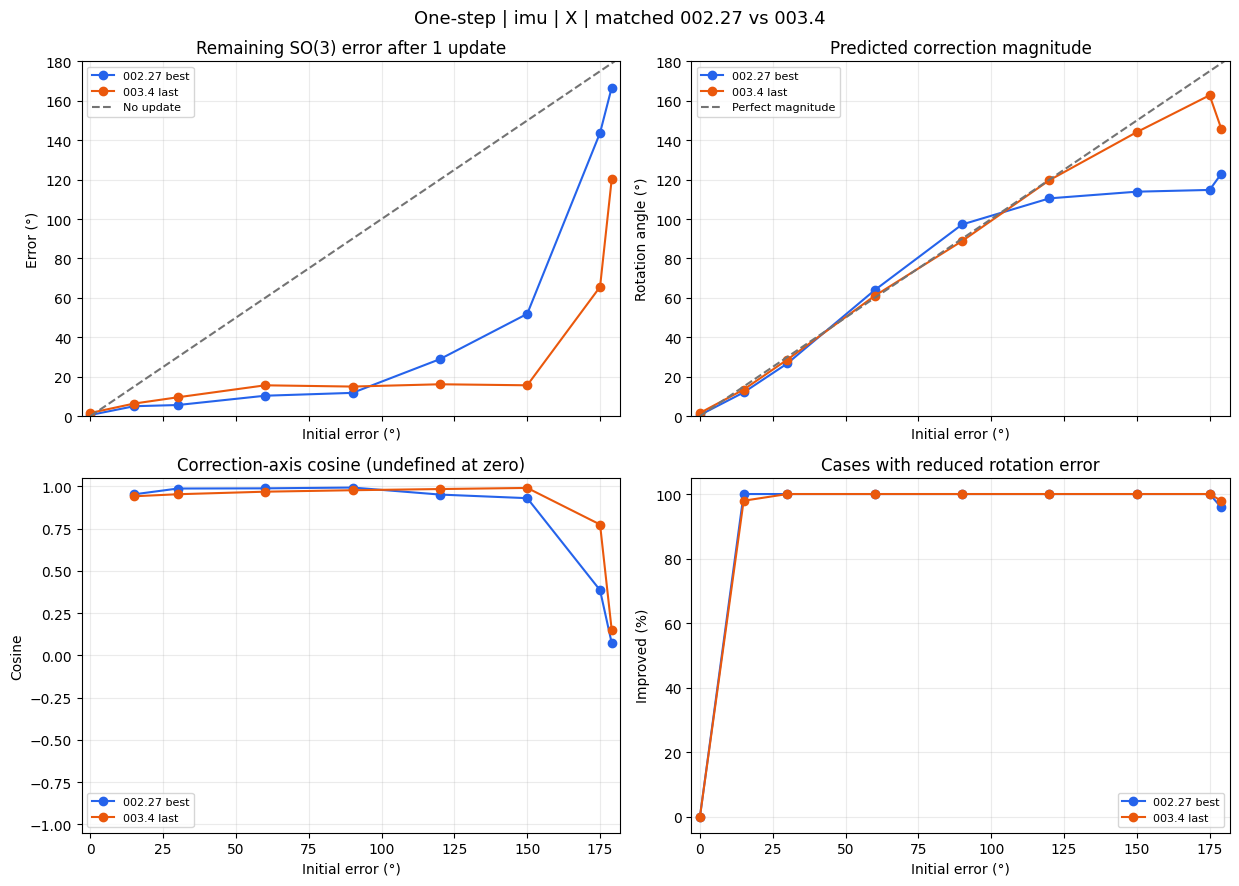

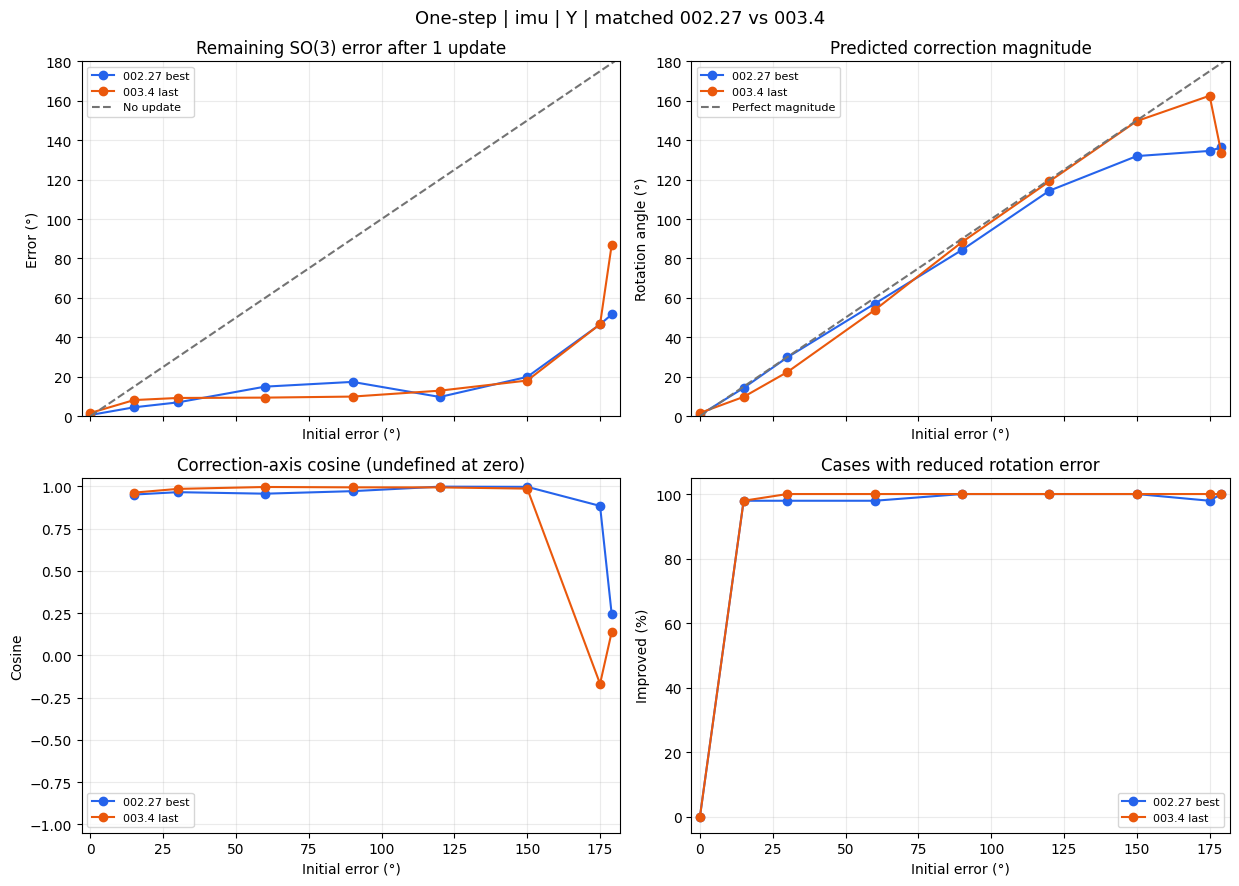

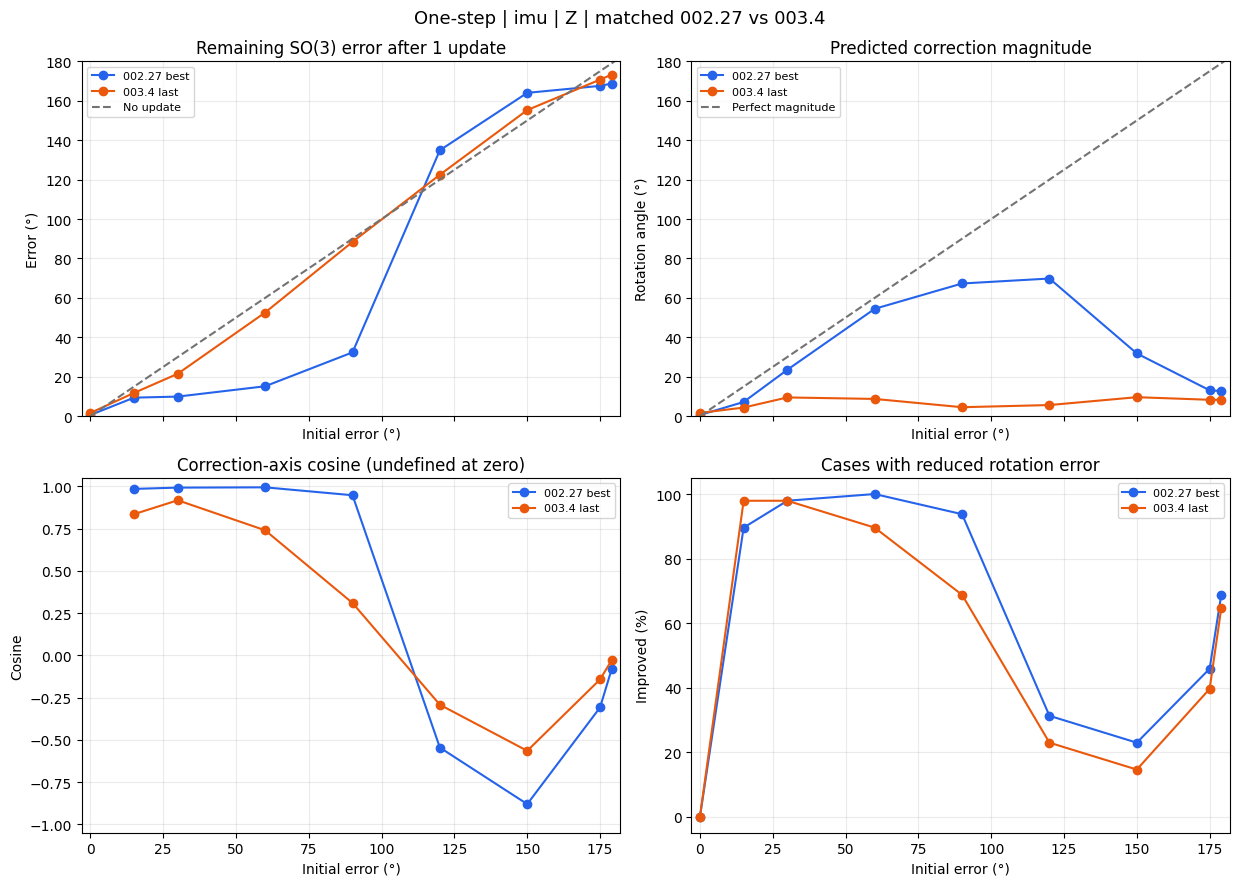

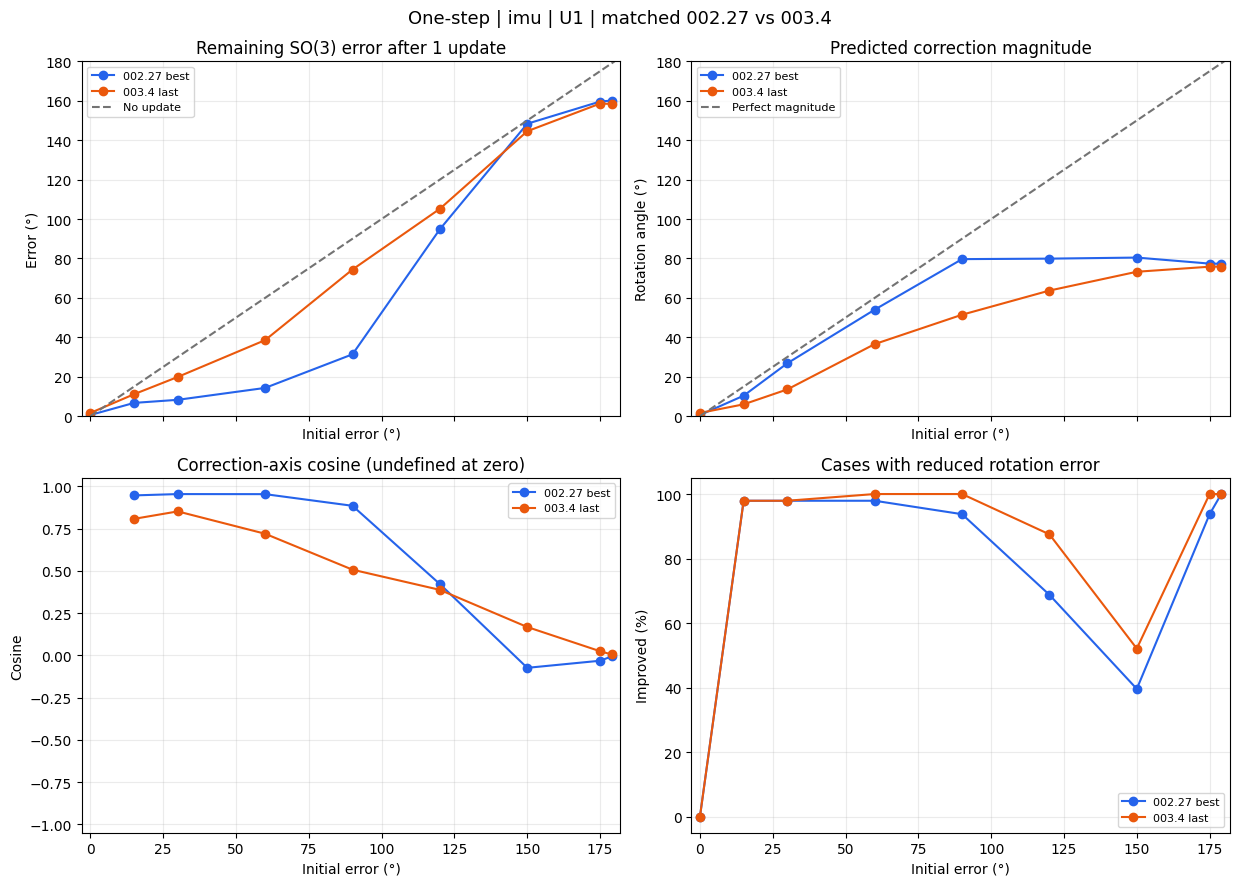

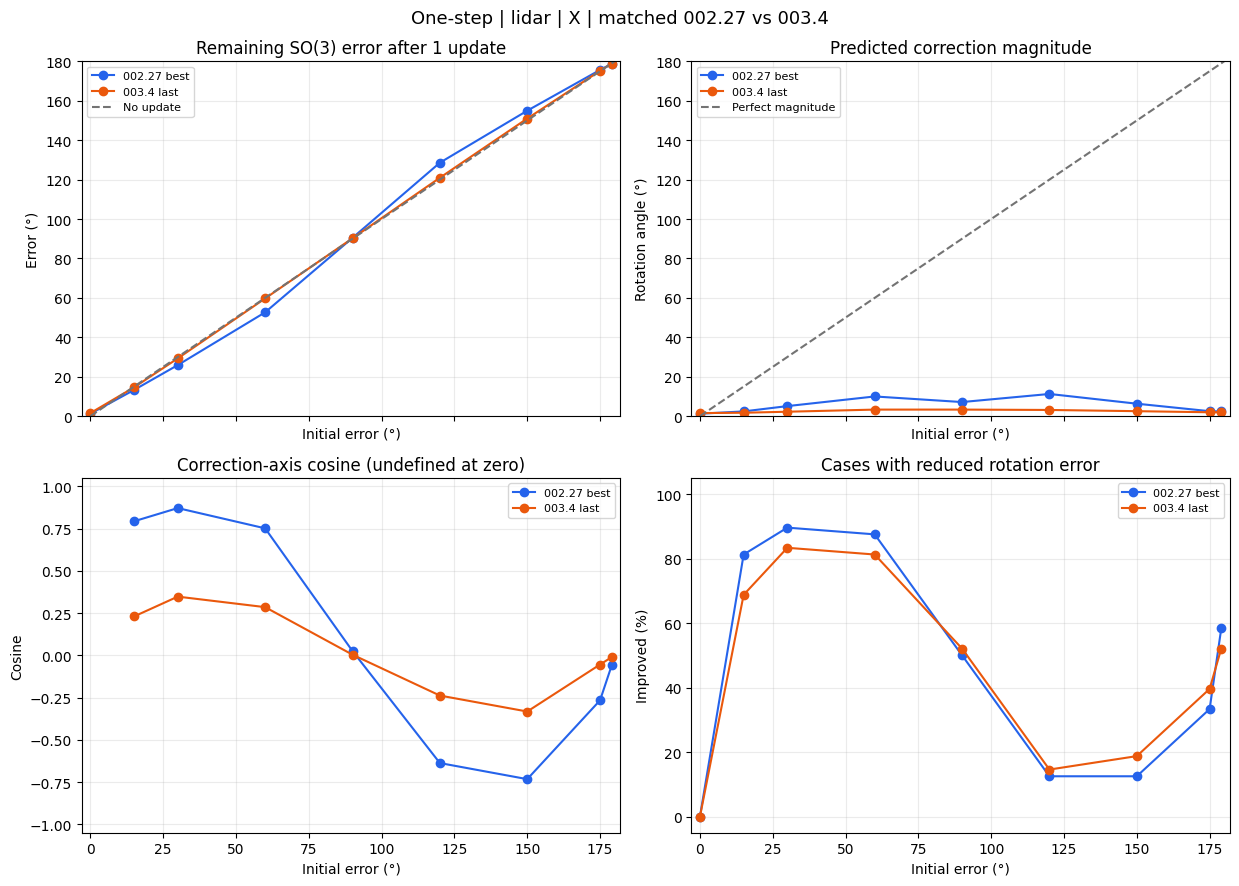

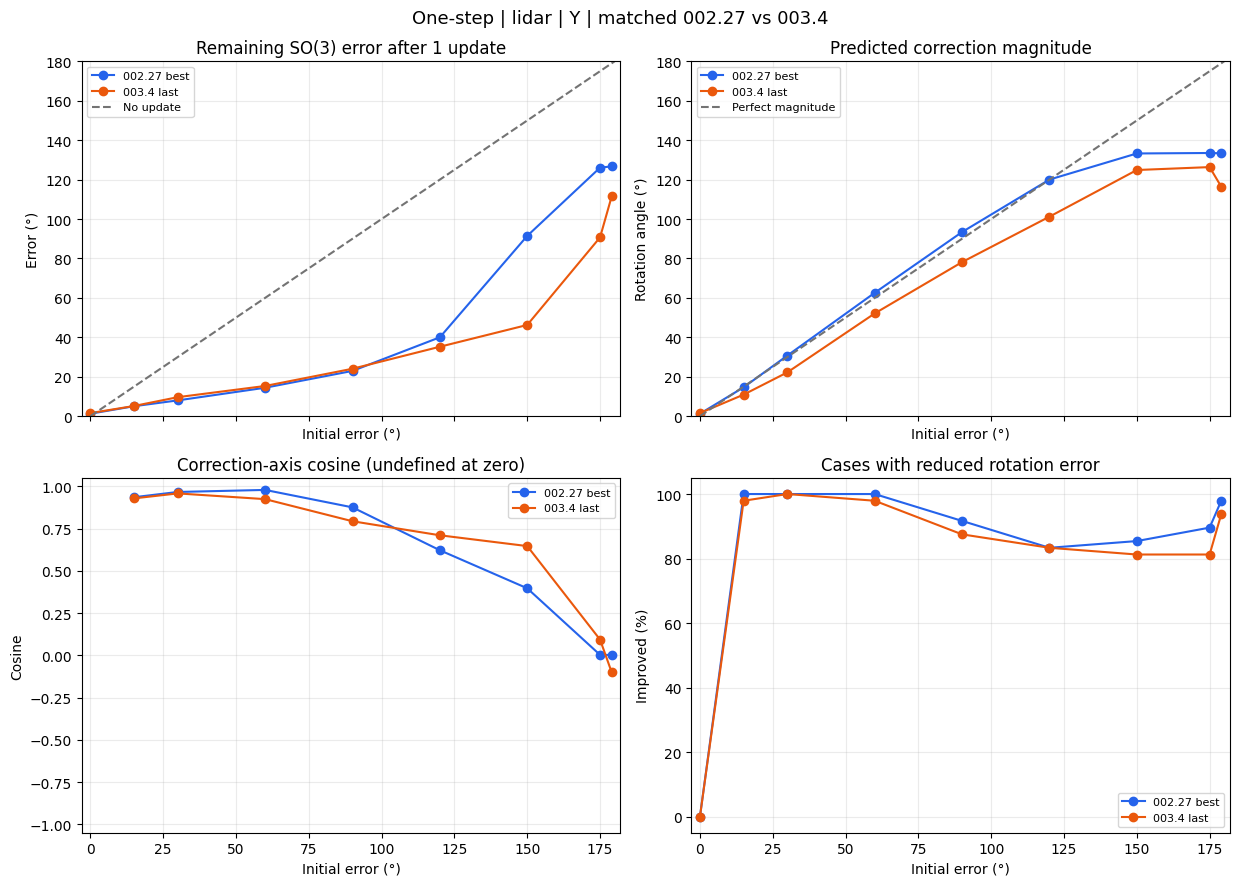

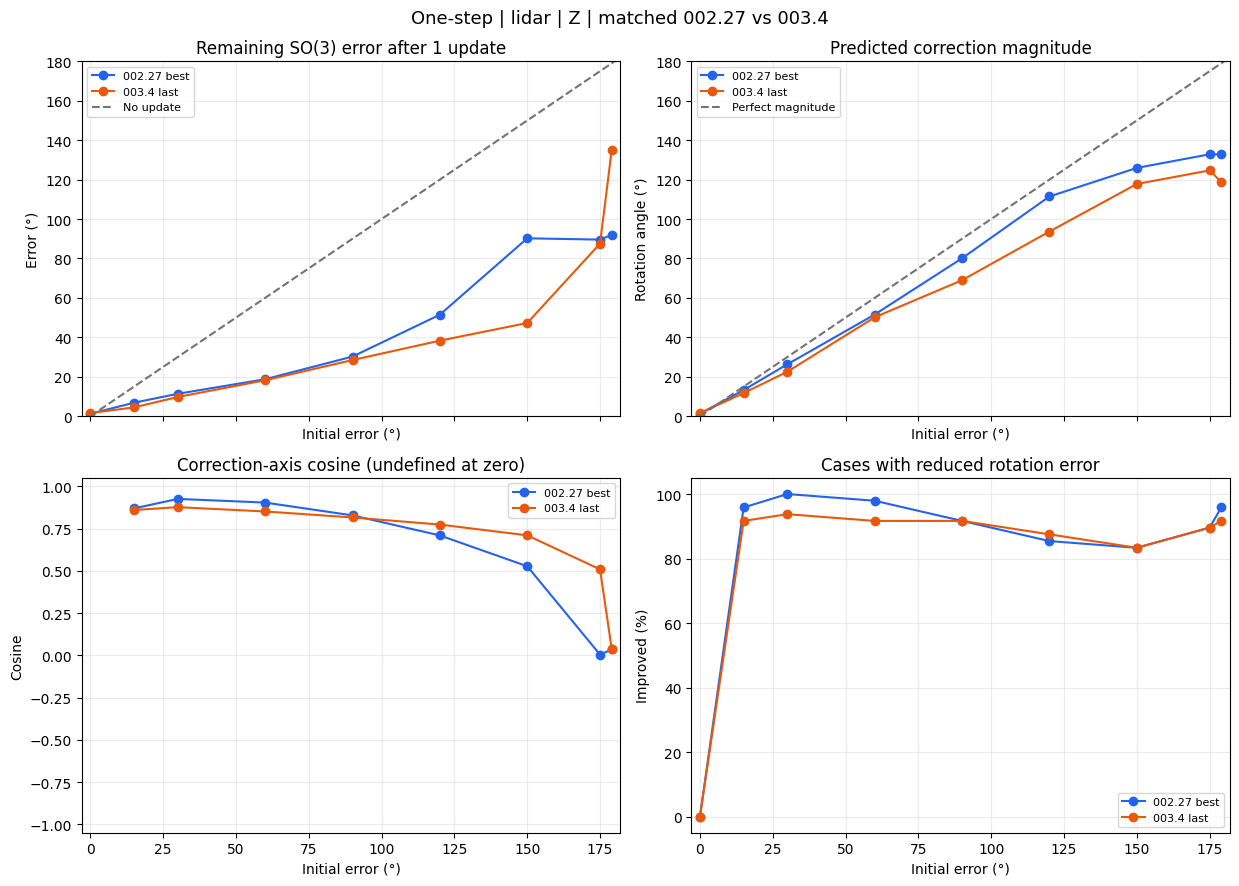

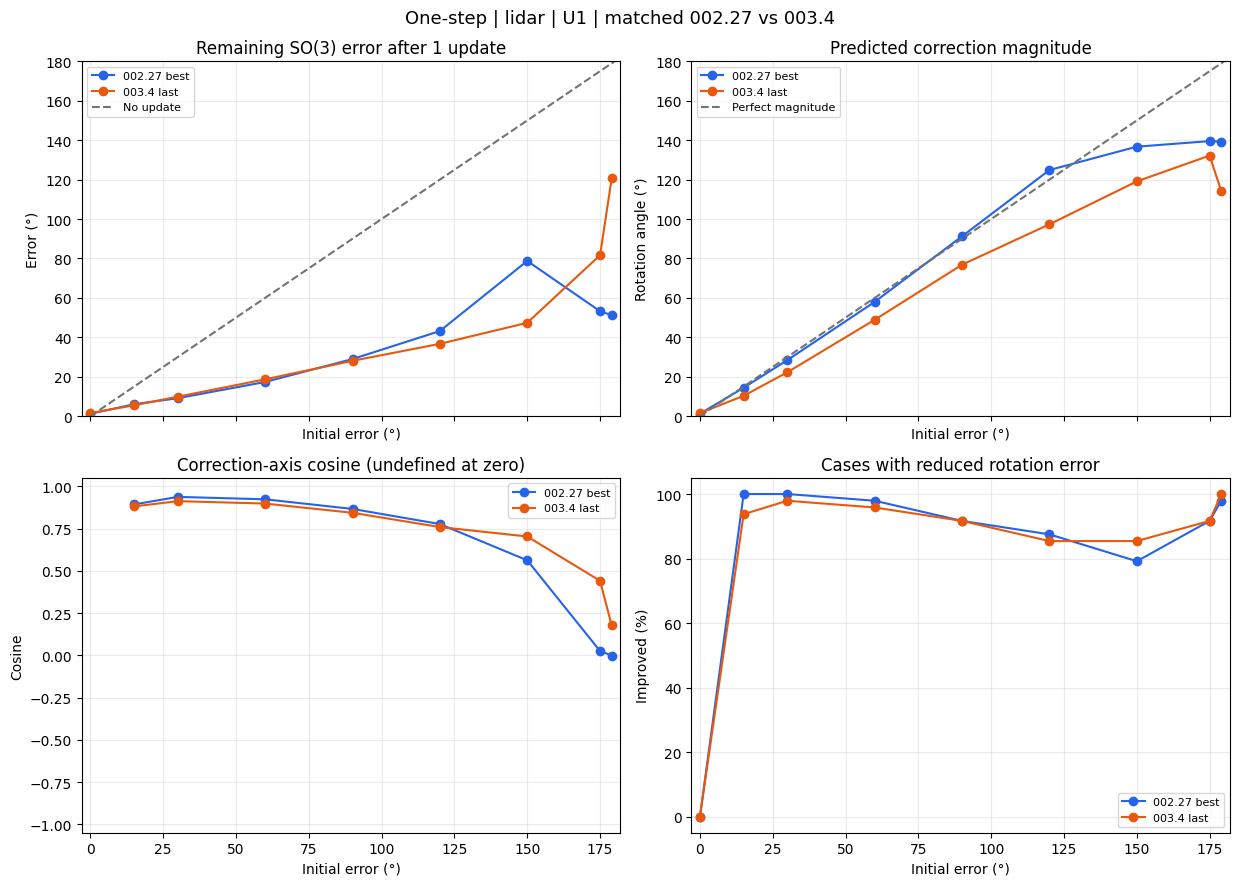

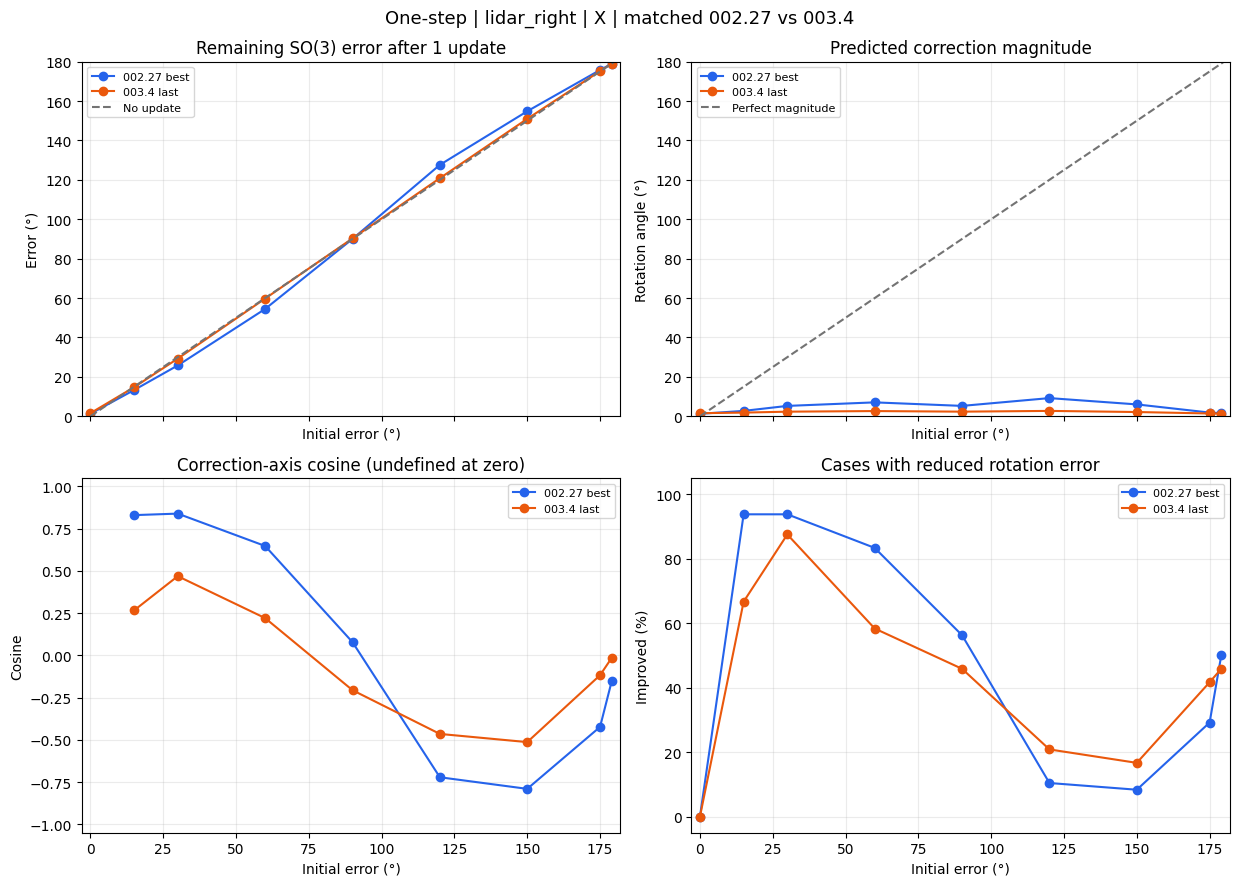

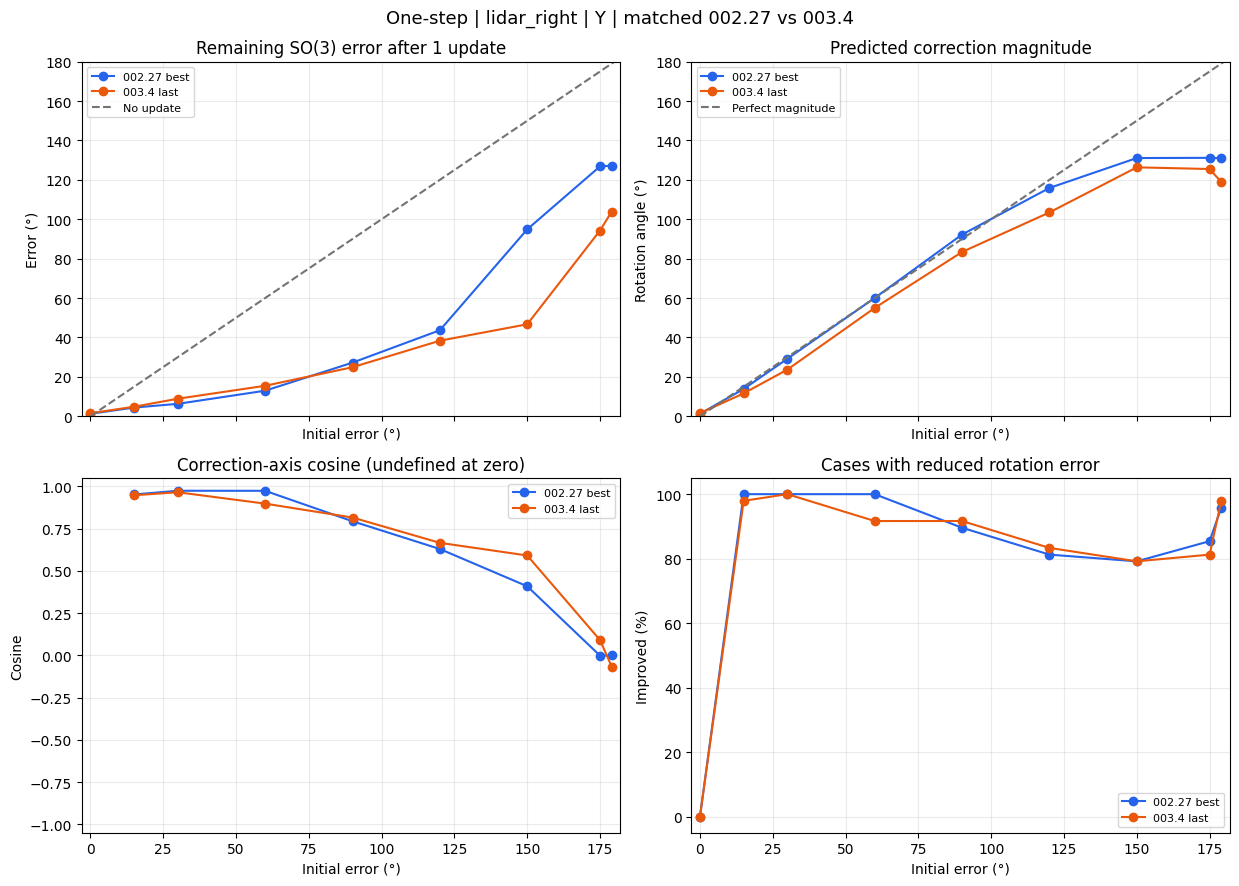

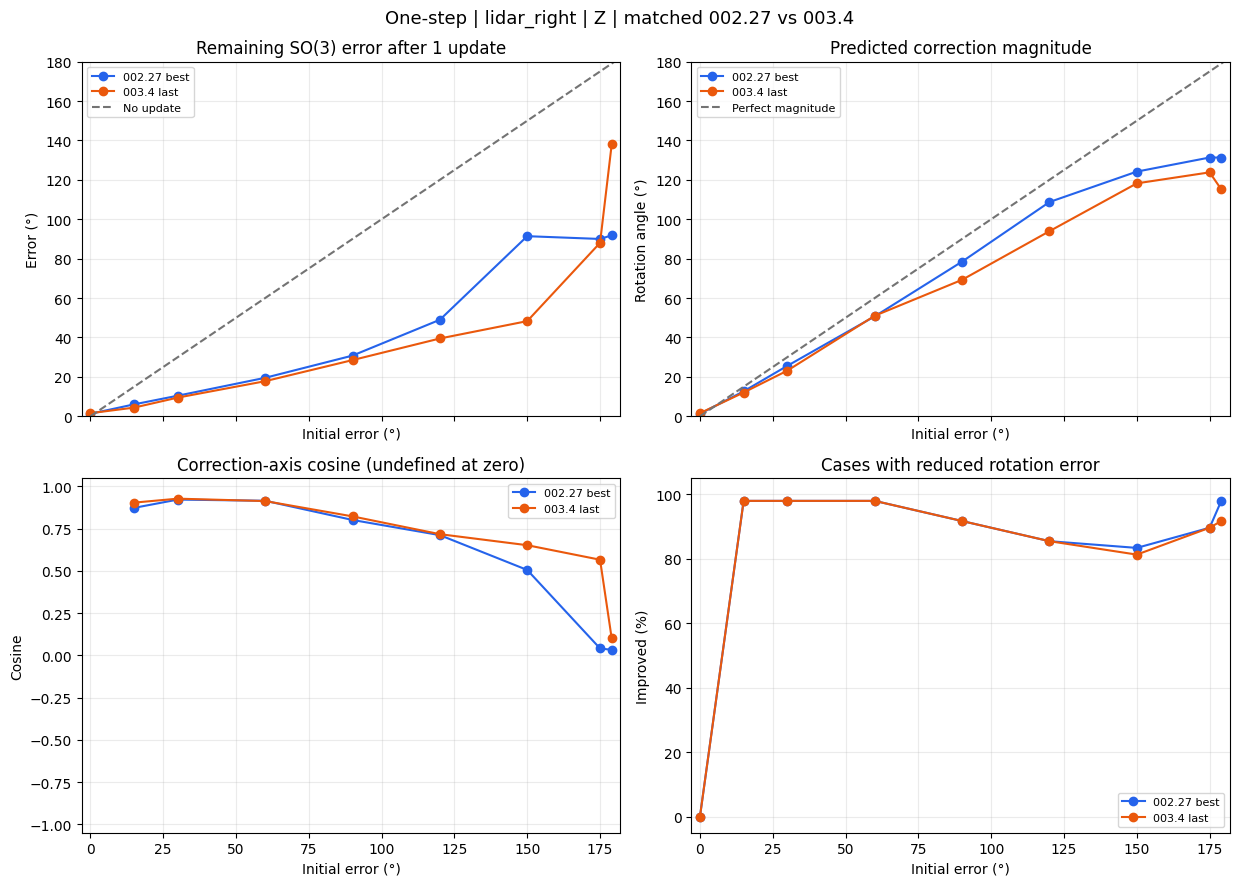

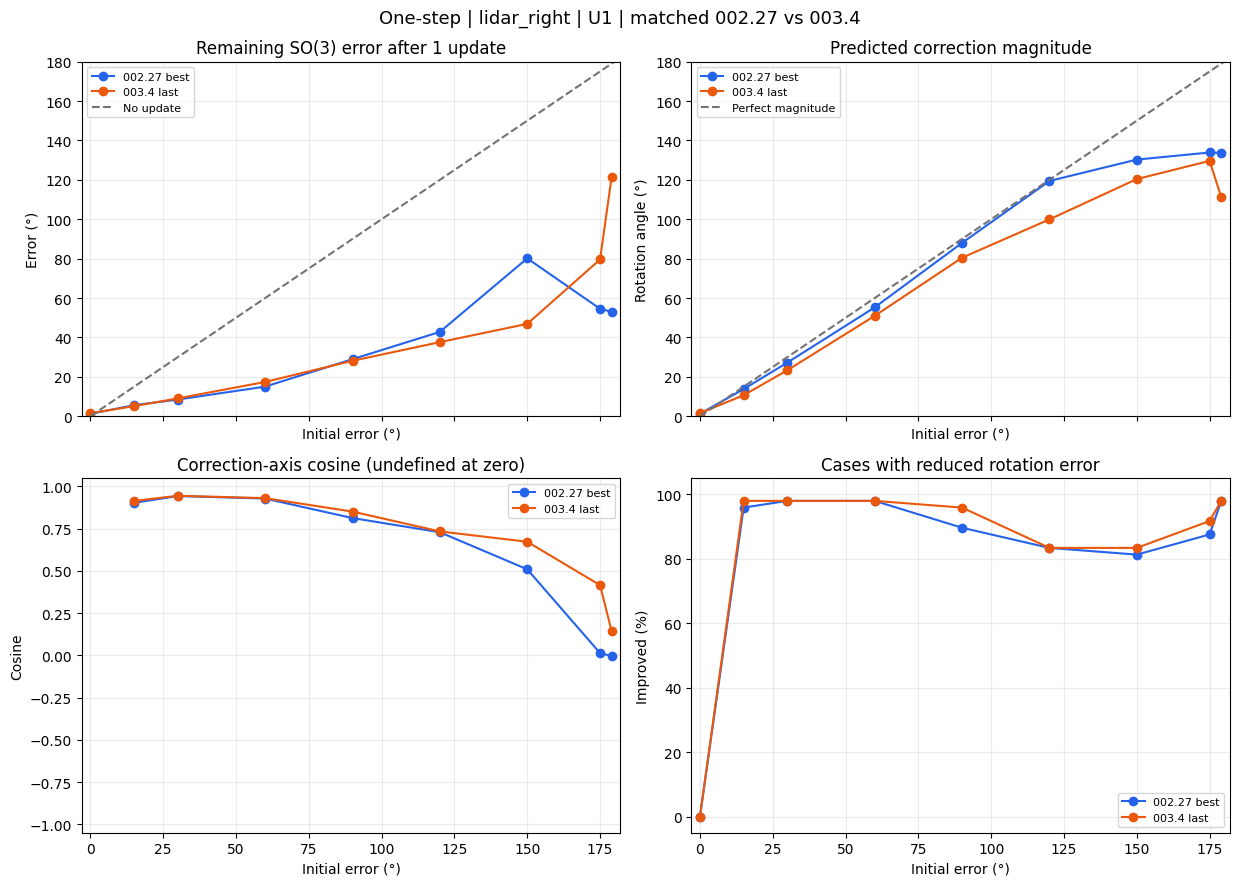

In [9]:
def finish_figure(fig, filename):
    fig.tight_layout()
    if SAVE_PLOTS:
        fig.savefig(OUTPUT_DIR / filename, dpi=PLOT_DPI, bbox_inches='tight')
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)


for sensor in FAULT_KEYS:
    for axis_name in AXIS_NAMES:
        fig, axs = plt.subplots(2,2,figsize=(12.5,9.0),sharex=True)
        for name in MODEL_ORDER:
            curve = one_step_summary[(one_step_summary.model==name)&(one_step_summary.sensor==sensor)&(one_step_summary.axis==axis_name)].sort_values('angle_deg')
            x = curve.angle_deg.to_numpy()
            axs[0,0].plot(x,curve.mean_residual_deg,'-o',color=COLORS[name],label=name)
            axs[0,1].plot(x,curve.predicted_magnitude_deg,'-o',color=COLORS[name],label=name)
            axs[1,0].plot(x,curve.axis_cos,'-o',color=COLORS[name],label=name)
            axs[1,1].plot(x,100*curve.improved_fraction,'-o',color=COLORS[name],label=name)
        for ax in (axs[0,0],axs[0,1]):
            ax.plot([0,180],[0,180],'--',color='0.45',label='No update' if ax is axs[0,0] else 'Perfect magnitude')
        axs[0,0].set(title='Remaining SO(3) error after 1 update',ylabel='Error (°)',ylim=(0,180))
        axs[0,1].set(title='Predicted correction magnitude',ylabel='Rotation angle (°)',ylim=(0,180))
        axs[1,0].set(title='Correction-axis cosine (undefined at zero)',ylabel='Cosine',ylim=(-1.05,1.05))
        axs[1,1].set(title='Cases with reduced rotation error',ylabel='Improved (%)',ylim=(-5,105))
        for ax in axs.flat:
            ax.set(xlim=(-3,182),xlabel='Initial error (°)')
            ax.grid(alpha=.25)
            ax.legend(fontsize=8)
        fig.suptitle(f'One-step | {sensor} | {axis_name} | matched 002.27 vs 003.4',fontsize=13)
        finish_figure(fig,f'one_step_{sensor}_{axis_name}.png')

## 8. Chronological 12-window rollout bank

Each rollout reuses the **same physical 5-second measurements** for both checkpoints, with one consistent, randomly re-expressed true calibration across all 12 windows. The initial fault is injected only once. Subsequent windows see the calibration produced by the previous network prediction. By default only the faulted sensor is updated, matching the `update_all=False, rotation_only` diagnostics from Notebook 66. `0°` cases measure unwanted correction drift, not a missing improvement percentage.

For memory efficiency, multiple angles/signs are batched. All cases within a batch share exactly the same physical measurement sequence and reference calibration; only their current *prior* differs. The `SensorStreamBatch` data are repeated along the batch axis after physical augmentation, not resampled.

In [10]:
def repeat_window(physical, n):
    """Replicate an already augmented B=1 physical scene into B=n exact copies."""
    if n == 1:
        return with_states(physical, copy_states(physical.current_calibration))
    streams = {}
    for key, stream in physical.streams.items():
        assert stream.values.shape[0] == 1 and stream.timestamps.shape[0] == 1
        streams[key] = SensorStreamBatch(
            values=stream.values.repeat_interleave(n,dim=0),
            timestamps=stream.timestamps.repeat_interleave(n,dim=0),
            sample_mask=stream.sample_mask.repeat_interleave(n,dim=0),
            interval_start_timestamps=None if stream.interval_start_timestamps is None else stream.interval_start_timestamps.repeat_interleave(n,dim=0),
        )
    states = {key: CalibrationState(transform=state.transform.repeat_interleave(n,dim=0), time_offset=state.time_offset.repeat_interleave(n,dim=0)) for key,state in physical.current_calibration.items()}
    return WindowBatch(streams=streams, current_calibration=states, metadata=dict(physical.metadata), targets=None, dataset_indices=None)


def all_signed_fault_cases():
    return [(float(angle), int(sign)) for angle in ANGLES_DEG for sign in ((1,) if angle==0 else (-1,1))]


@torch.inference_mode()
def make_chronological_bank():
    bank=[]
    for seq_index, seq_name in enumerate(EVAL_SEQUENCES):
        indices = np.asarray(eval_dataset.window_indices_for_sequence(seq_name),dtype=int)
        maximum_start=len(indices)-ROLLOUT_NUM_WINDOWS
        positions=np.unique(np.linspace(0,maximum_start,min(ROLLOUT_STARTS_PER_SEQUENCE,maximum_start+1)).round().astype(int))
        for start_number, start_pos in enumerate(positions):
            chosen=indices[start_pos:start_pos+ROLLOUT_NUM_WINDOWS]
            seed=ROLLOUT_PHYSICAL_SEED+seq_index*100003+start_number*1009
            windows=[]
            for index in chosen:
                base=window_batch_to(collate_windows([eval_dataset[int(index)]]),DEVICE,dtype=MODEL_DTYPE)
                physical=physical_augmenter(base,generator=seeded_generator(seed)).augmented_window
                windows.append(physical)
            truth=windows[0].current_calibration
            for next_window in windows[1:]:
                for key in CALIBRATION_KEYS:
                    torch.testing.assert_close(next_window.current_calibration[key].transform,truth[key].transform,atol=3e-5,rtol=3e-5)
                    torch.testing.assert_close(next_window.current_calibration[key].time_offset,truth[key].time_offset,atol=3e-6,rtol=3e-6)
            bank.append(dict(sequence=seq_name,start_index=int(chosen[0]), indices=chosen,windows=windows,seed=seed))
    return bank

rollout_bank=make_chronological_bank()
print('Rollout starts:',[(b['sequence'],b['start_index']) for b in rollout_bank])
print('Per rollout:',ROLLOUT_NUM_WINDOWS,'consecutive physical windows; angle/sign cases:',len(all_signed_fault_cases()))

Rollout starts: [('Urban26', 0), ('Urban26', 82), ('Urban28', 94), ('Urban28', 406)]
Per rollout: 12 consecutive physical windows; angle/sign cases: 17


## 9. Batched two-checkpoint chronological rollouts and case-level metrics

In [11]:
@torch.inference_mode()
def batched_fault_prior(truth_states, fault_key, axis, cases):
    states=copy_states(truth_states)
    signed_deg=torch.tensor([angle*sign for angle,sign in cases],device=DEVICE,dtype=MODEL_DTYPE)
    T=states[fault_key].transform.clone()
    T[:,:3,:3]=so3_exp(signed_deg[:,None]*np.pi/180.0*axis[None,:])@T[:,:3,:3]
    states[fault_key]=replace(states[fault_key],transform=T)
    return states


@torch.inference_mode()
def apply_rotation_updates(states, corrections, fault_key):
    keys=CALIBRATION_KEYS if ROLLOUT_UPDATE_ALL_KEYS else (fault_key,)
    updated=dict(states)
    for key in keys:
        state=states[key]
        T=state.transform.clone()
        T[:,:3,:3]=corrections[key]@state.transform[:,:3,:3]
        updated[key]=replace(state,transform=T)
    return updated


@torch.inference_mode()
def evaluate_rollouts():
    rows=[]
    cases=all_signed_fault_cases()
    for bank_index,entry in enumerate(rollout_bank):
        truth=entry['windows'][0].current_calibration
        for key in FAULT_KEYS:
            for axis_name in AXIS_NAMES:
                axis=AXES[axis_name]
                for offset in range(0,len(cases),ROLLOUT_CASE_BATCH_SIZE):
                    selected=cases[offset:offset+ROLLOUT_CASE_BATCH_SIZE]
                    n=len(selected)
                    repeated=[repeat_window(physical,n) for physical in entry['windows']]
                    truth_n=repeated[0].current_calibration
                    prior0=batched_fault_prior(truth_n,key,axis,selected)
                    true_R=truth_n[key].transform[:,:3,:3]
                    initial_error=distance_so3_deg(prior0[key].transform[:,:3,:3],true_R)
                    expected=torch.tensor([angle for angle,_ in selected],device=DEVICE,dtype=MODEL_DTYPE)
                    if float((initial_error-expected).abs().max())>0.2:
                        raise AssertionError(f'Fault mismatch: {key}/{axis_name}/{selected}')
                    for model_name in MODEL_ORDER:
                        states=copy_states(prior0)
                        for step in range(ROLLOUT_NUM_WINDOWS+1):
                            active_error=distance_so3_deg(states[key].transform[:,:3,:3],true_R)
                            if ROLLOUT_UPDATE_ALL_KEYS:
                                healthy_error=torch.stack([distance_so3_deg(states[other].transform[:,:3,:3],truth_n[other].transform[:,:3,:3]) for other in CALIBRATION_KEYS if other!=key],dim=0).mean(dim=0)
                            else:
                                healthy_error=torch.zeros_like(active_error)
                            for j,(angle,sign) in enumerate(selected):
                                a=float(active_error[j]); h=float(healthy_error[j])
                                rows.append(dict(model=model_name,sequence=entry['sequence'],start_index=entry['start_index'],sensor=key,axis=axis_name,
                                                 angle_deg=float(angle),sign=int(sign),step=int(step),elapsed_s=float(step*WINDOW_STRIDE_S),
                                                 residual_deg=a,gain_deg=float(angle)-a,healthy_error_deg=h,
                                                 success_10deg=bool(a<10),improved=bool(a<float(angle)-1e-4)))
                            if step==ROLLOUT_NUM_WINDOWS:
                                break
                            input_window=with_states(repeated[step],states)
                            corrections=predicted_rotation_matrices(input_window,model_name)
                            states=apply_rotation_updates(states,corrections,key)
                print(f'Rollouts {bank_index+1}/{len(rollout_bank)} | {entry["sequence"]} index={entry["start_index"]} | {key}/{axis_name}',flush=True)
    result=pd.DataFrame(rows)
    result.to_csv(OUTPUT_DIR/'rollout_cases.csv',index=False)
    return result

rollout_df=evaluate_rollouts()
rollout_summary=rollout_df.groupby(['model','sensor','axis','angle_deg','step'],as_index=False).agg(
    n=('residual_deg','size'),mean_residual_deg=('residual_deg','mean'),median_residual_deg=('residual_deg','median'),
    p90_residual_deg=('residual_deg',lambda x:np.percentile(x,90)),success_10deg=('success_10deg','mean'),
    improved_fraction=('improved','mean'),healthy_error_deg=('healthy_error_deg','mean'))
rollout_summary.to_csv(OUTPUT_DIR/'rollout_summary.csv',index=False)
print('Total rollout rows:',len(rollout_df))
print('Mean final residual by sensor and axis:')
display(rollout_summary[(rollout_summary.step==ROLLOUT_NUM_WINDOWS)&rollout_summary.angle_deg.isin((0.,30.,90.,150.,179.))].round(1).head(40))

Rollouts 1/4 | Urban26 index=0 | imu/X
Rollouts 1/4 | Urban26 index=0 | imu/Y
Rollouts 1/4 | Urban26 index=0 | imu/Z
Rollouts 1/4 | Urban26 index=0 | imu/U1
Rollouts 1/4 | Urban26 index=0 | lidar/X
Rollouts 1/4 | Urban26 index=0 | lidar/Y
Rollouts 1/4 | Urban26 index=0 | lidar/Z
Rollouts 1/4 | Urban26 index=0 | lidar/U1
Rollouts 1/4 | Urban26 index=0 | lidar_right/X
Rollouts 1/4 | Urban26 index=0 | lidar_right/Y
Rollouts 1/4 | Urban26 index=0 | lidar_right/Z
Rollouts 1/4 | Urban26 index=0 | lidar_right/U1
Rollouts 2/4 | Urban26 index=82 | imu/X
Rollouts 2/4 | Urban26 index=82 | imu/Y
Rollouts 2/4 | Urban26 index=82 | imu/Z
Rollouts 2/4 | Urban26 index=82 | imu/U1
Rollouts 2/4 | Urban26 index=82 | lidar/X
Rollouts 2/4 | Urban26 index=82 | lidar/Y
Rollouts 2/4 | Urban26 index=82 | lidar/Z
Rollouts 2/4 | Urban26 index=82 | lidar/U1
Rollouts 2/4 | Urban26 index=82 | lidar_right/X
Rollouts 2/4 | Urban26 index=82 | lidar_right/Y
Rollouts 2/4 | Urban26 index=82 | lidar_right/Z
Rollouts 2/4 | 

,model,sensor,axis,angle_deg,step,n,mean_residual_deg,median_residual_deg,p90_residual_deg,success_10deg,improved_fraction,healthy_error_deg
12,002.27 best,imu,U1,0.0,12,4,2.9,2.4,5.3,1.0,0.0,0.0
38,002.27 best,imu,U1,30.0,12,8,2.9,2.3,6.1,1.0,1.0,0.0
64,002.27 best,imu,U1,90.0,12,8,25.5,4.8,57.7,0.9,0.9,0.0
90,002.27 best,imu,U1,150.0,12,8,132.8,172.3,177.6,0.2,0.2,0.0
116,002.27 best,imu,U1,179.0,12,8,132.8,172.2,177.5,0.2,1.0,0.0
129,002.27 best,imu,X,0.0,12,4,2.9,2.4,5.3,1.0,0.0,0.0
155,002.27 best,imu,X,30.0,12,8,3.3,2.8,6.2,1.0,1.0,0.0
181,002.27 best,imu,X,90.0,12,8,3.3,3.3,5.9,1.0,1.0,0.0
207,002.27 best,imu,X,150.0,12,8,3.3,3.2,5.7,1.0,1.0,0.0
233,002.27 best,imu,X,179.0,12,8,132.9,172.2,177.5,0.2,1.0,0.0


## 10. Rollout plots: separate X/Y/Z/U1 figures for each sensor

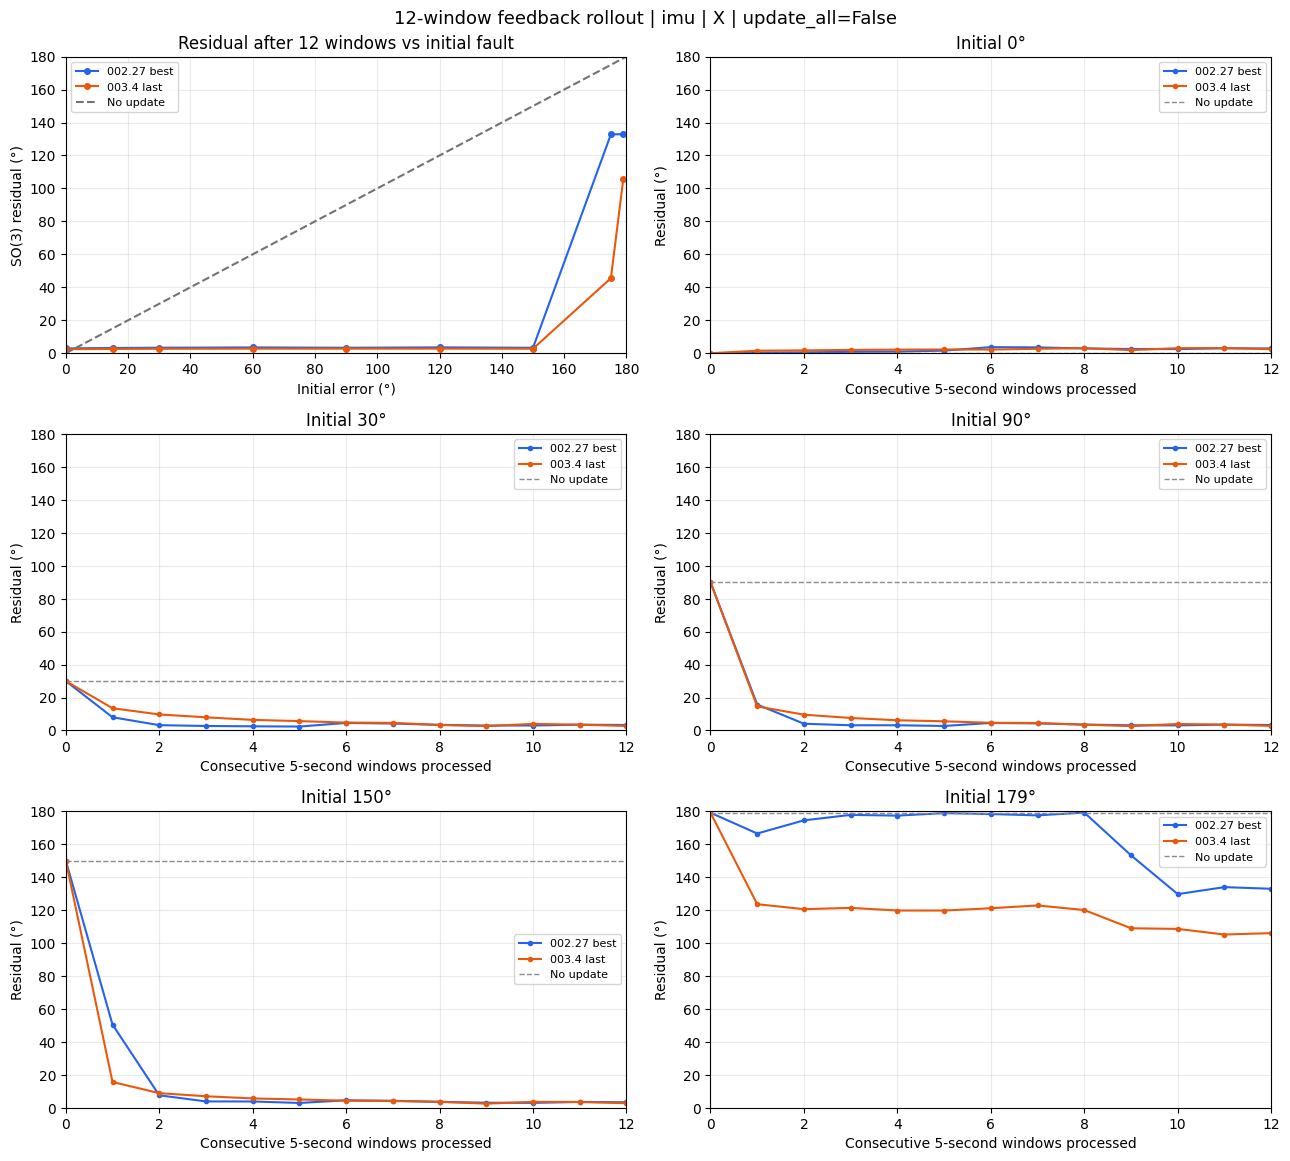

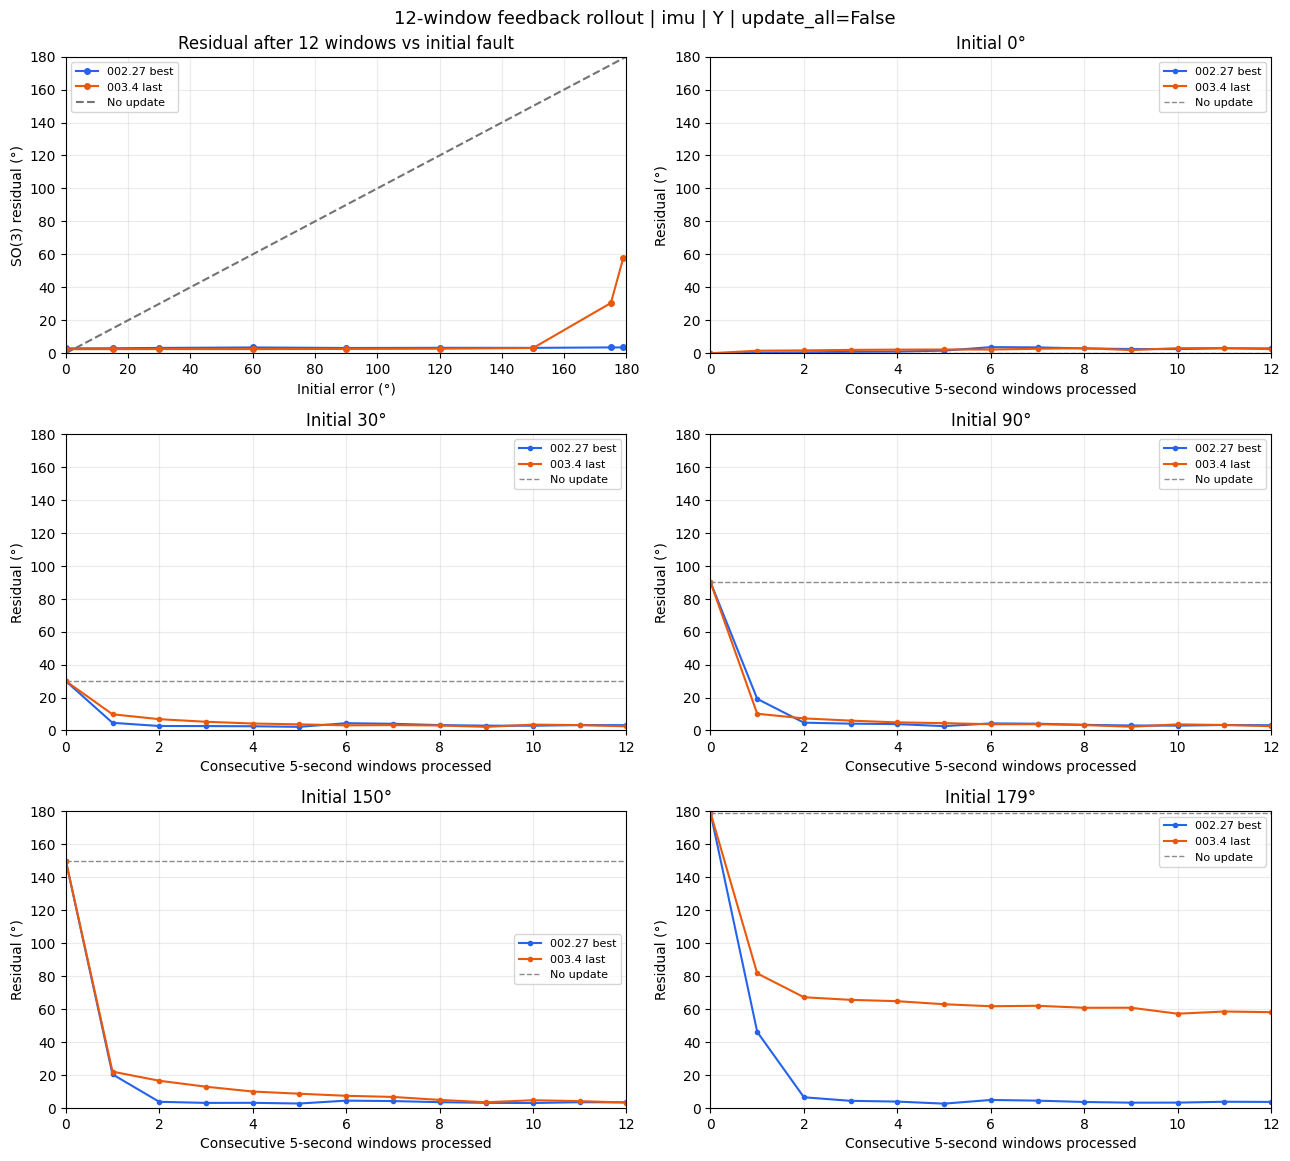

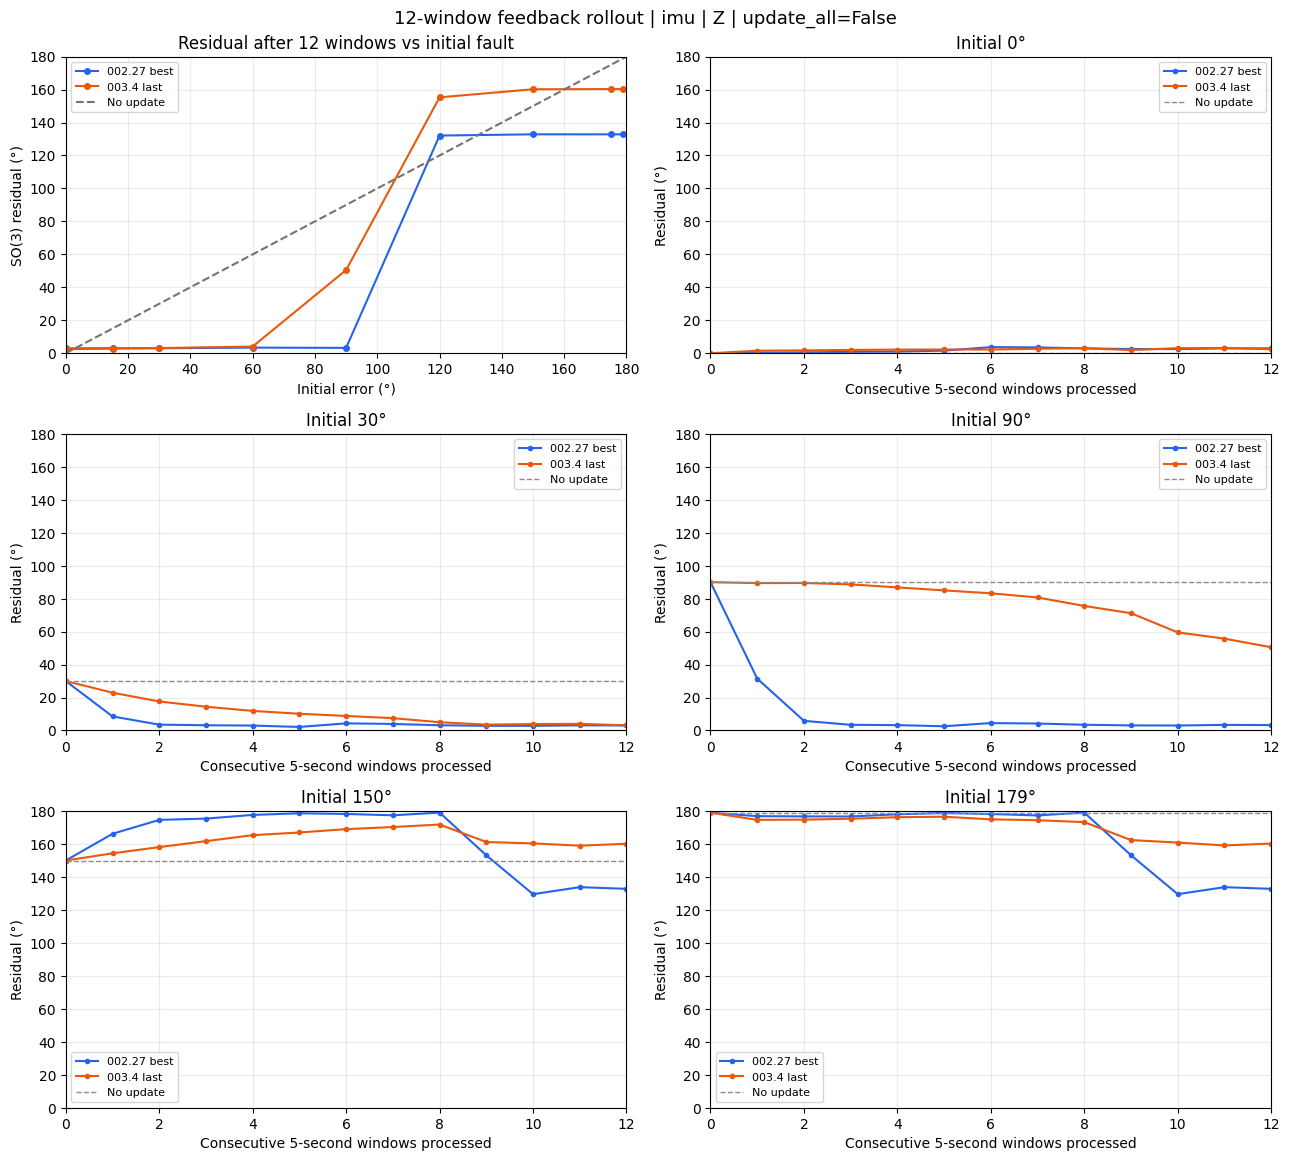

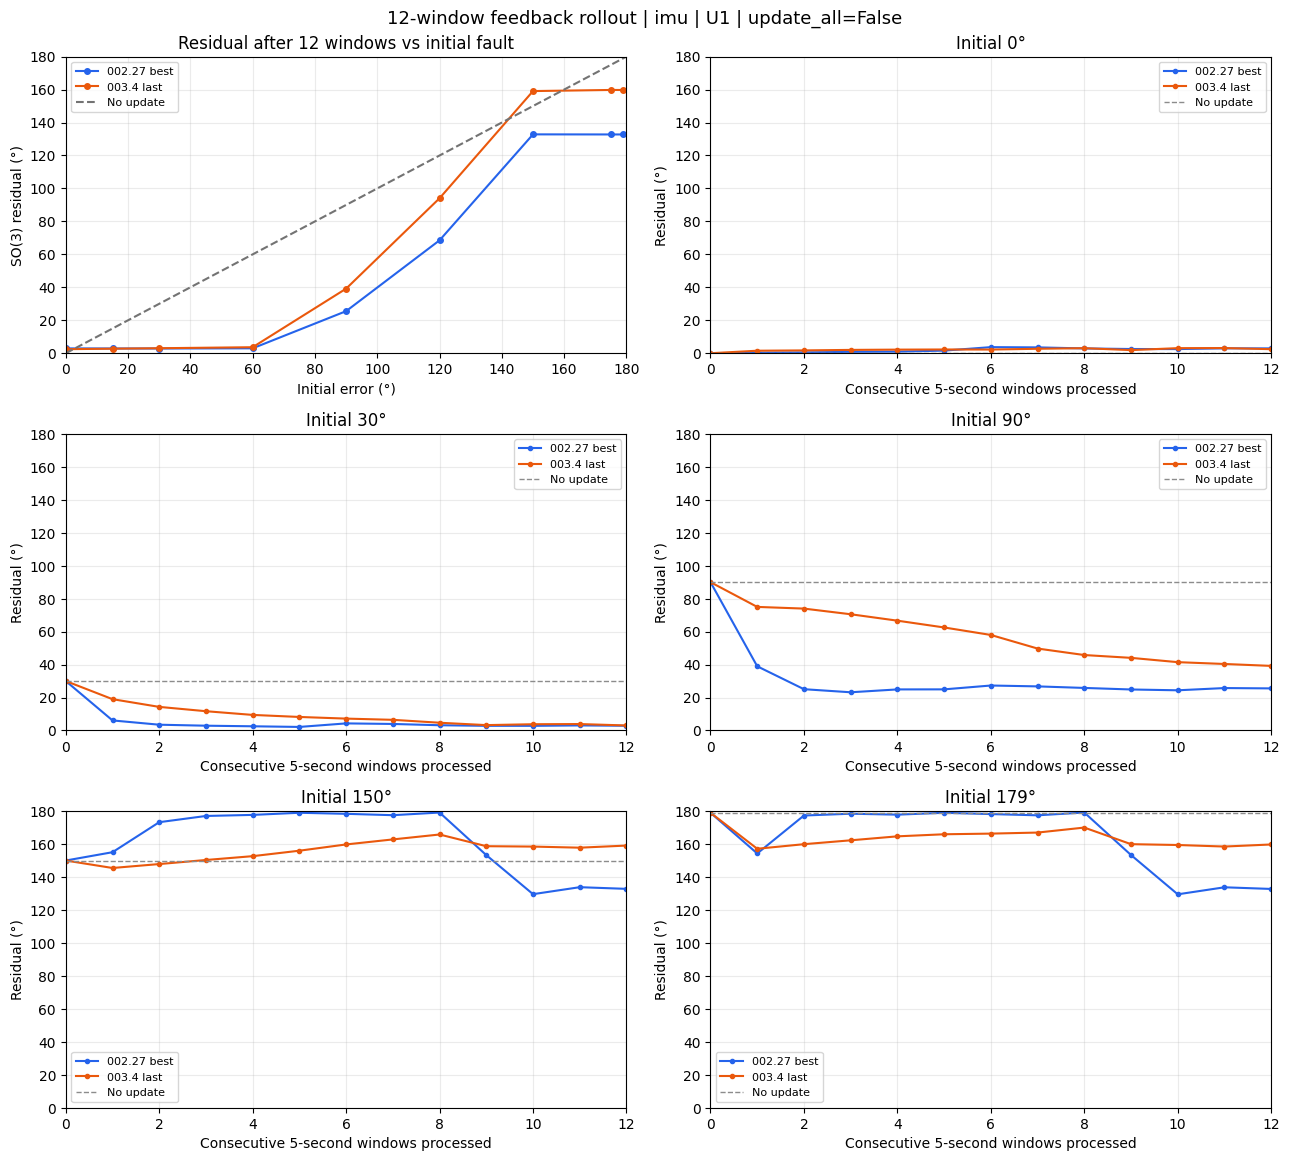

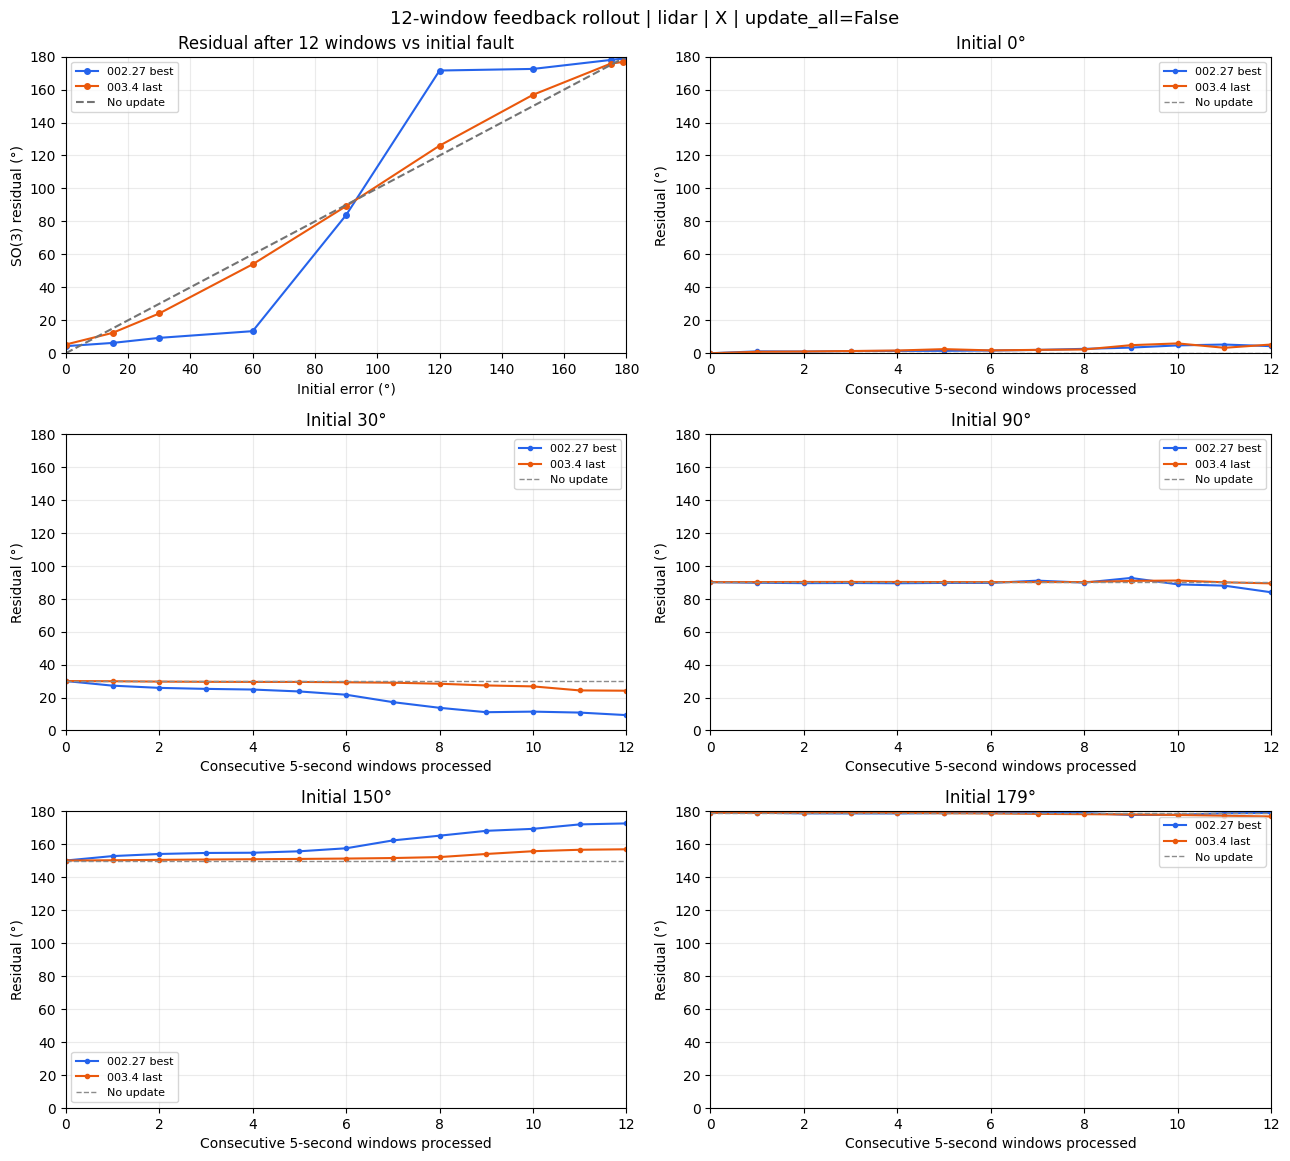

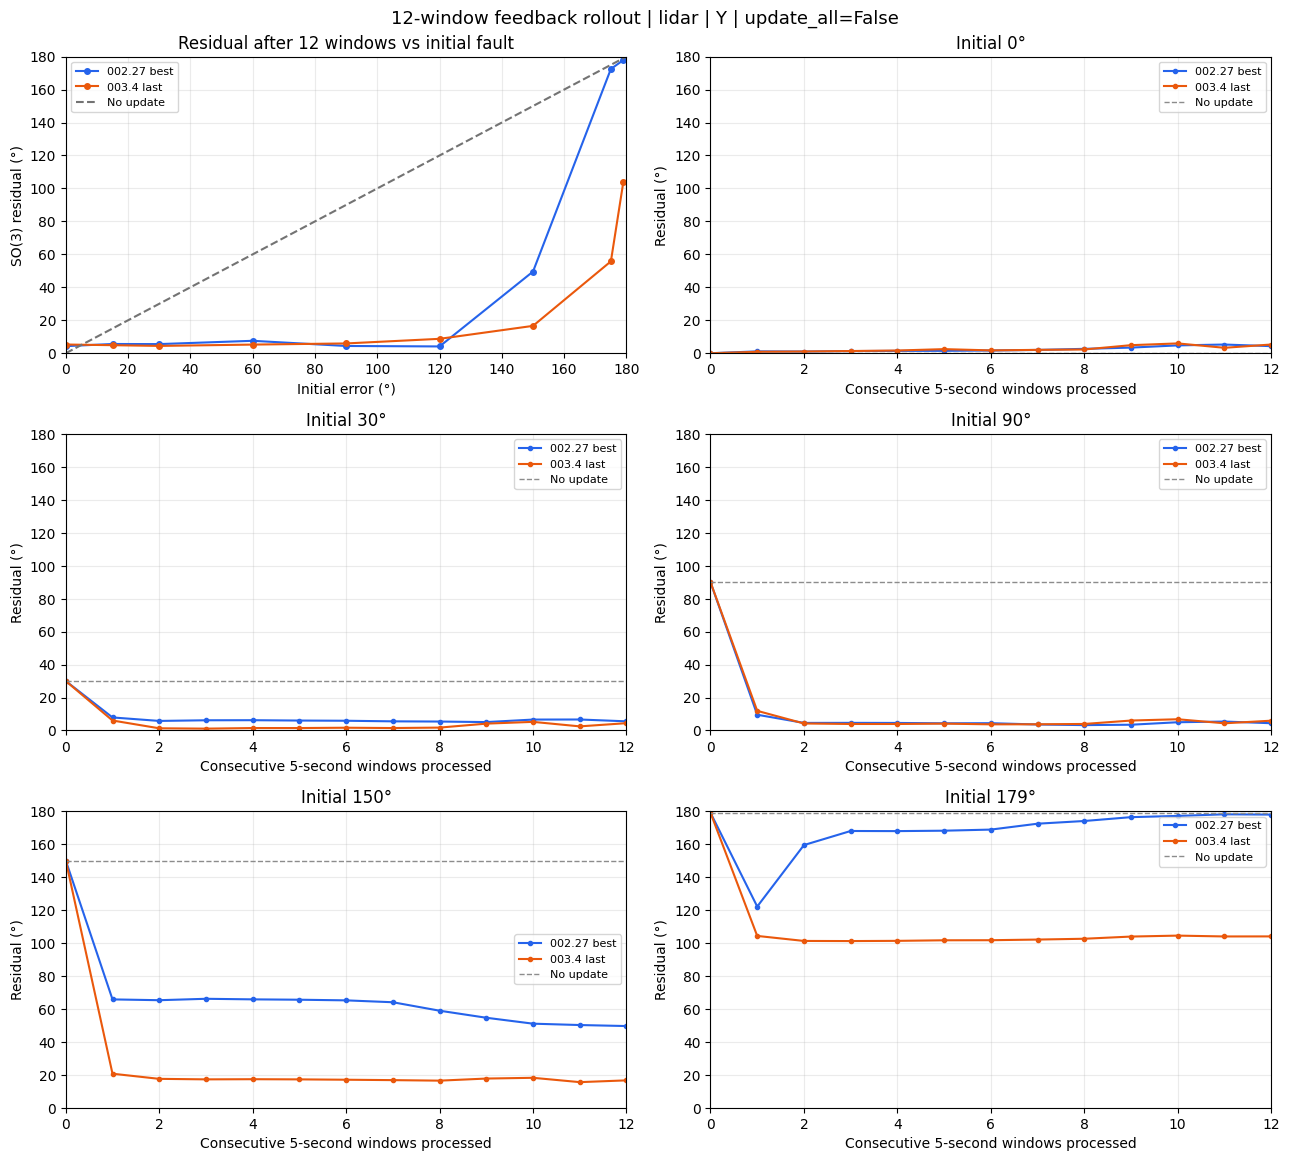

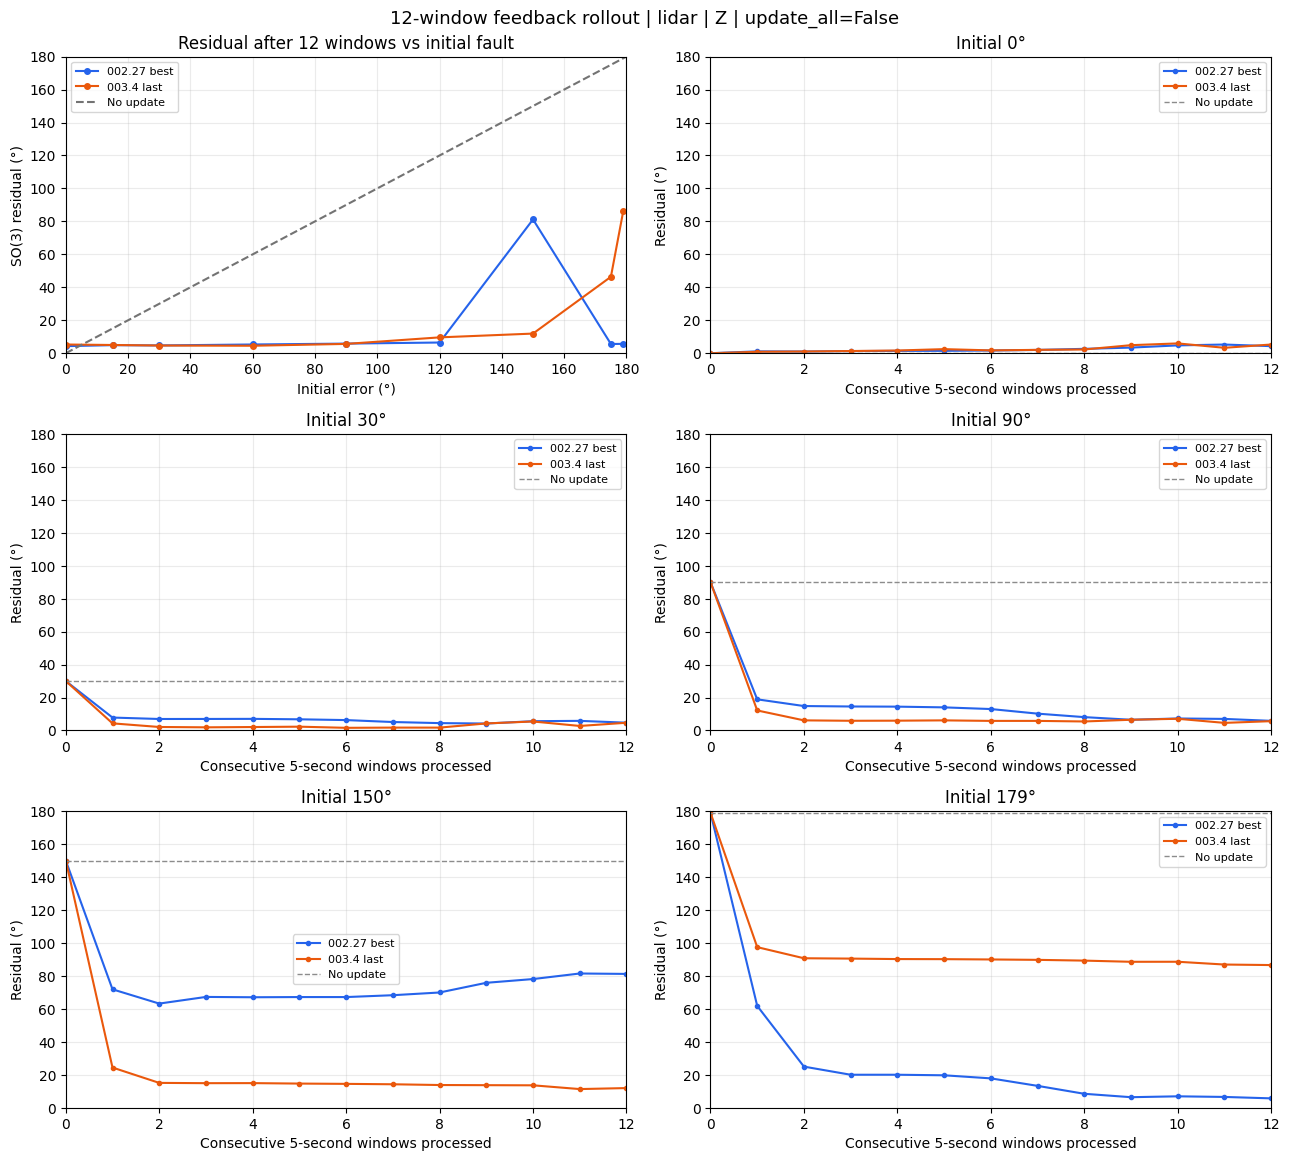

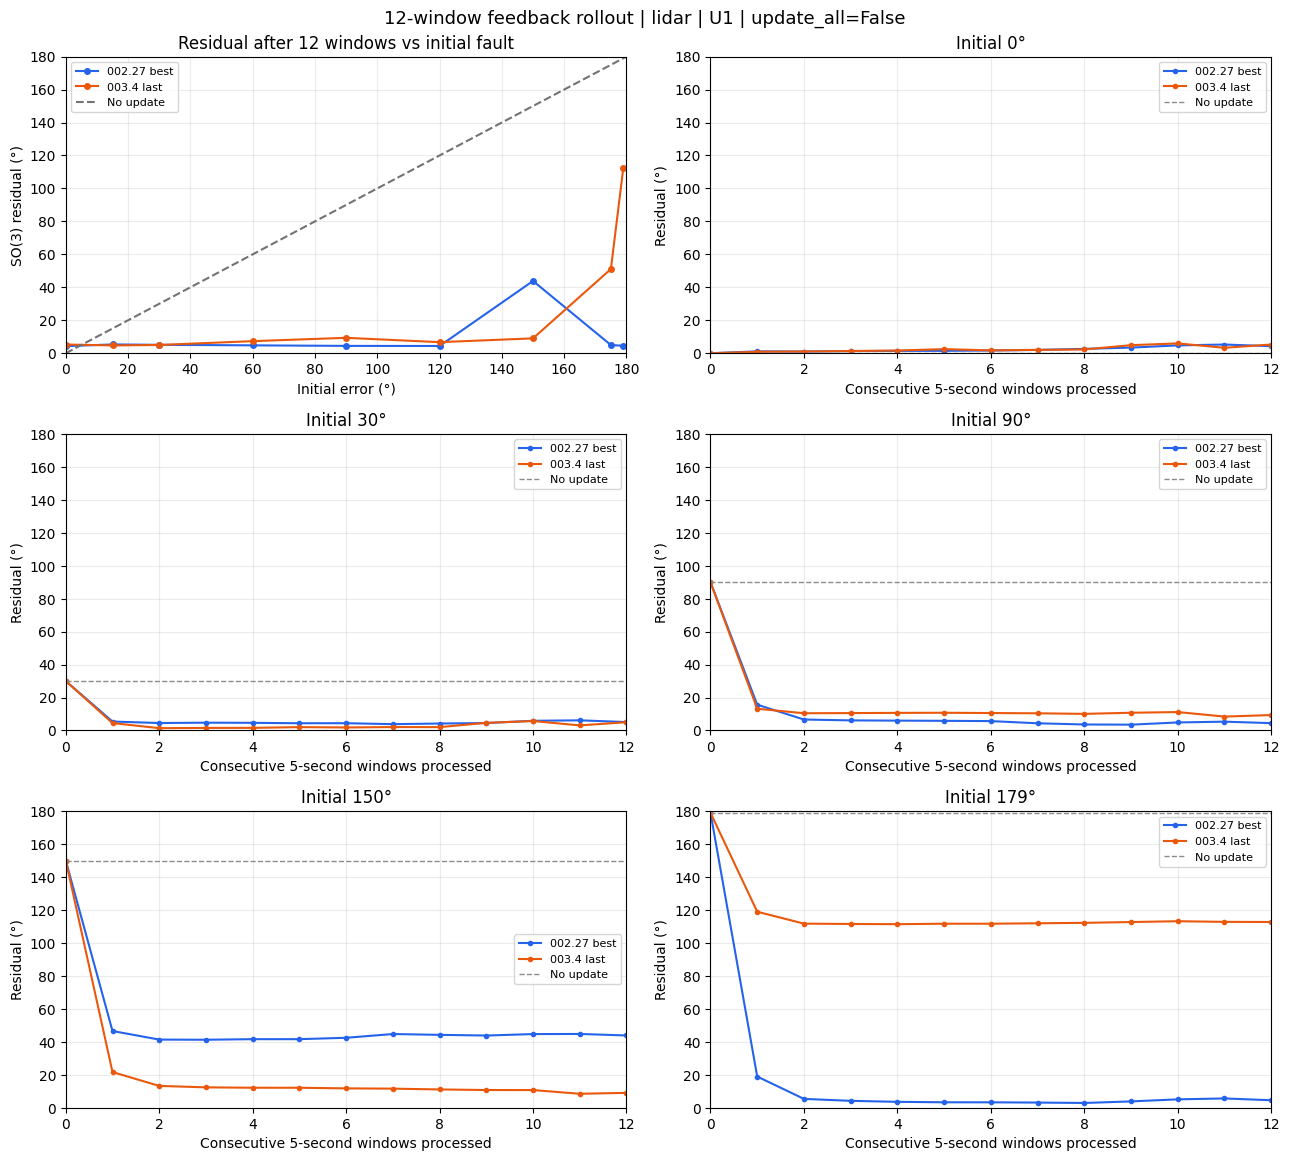

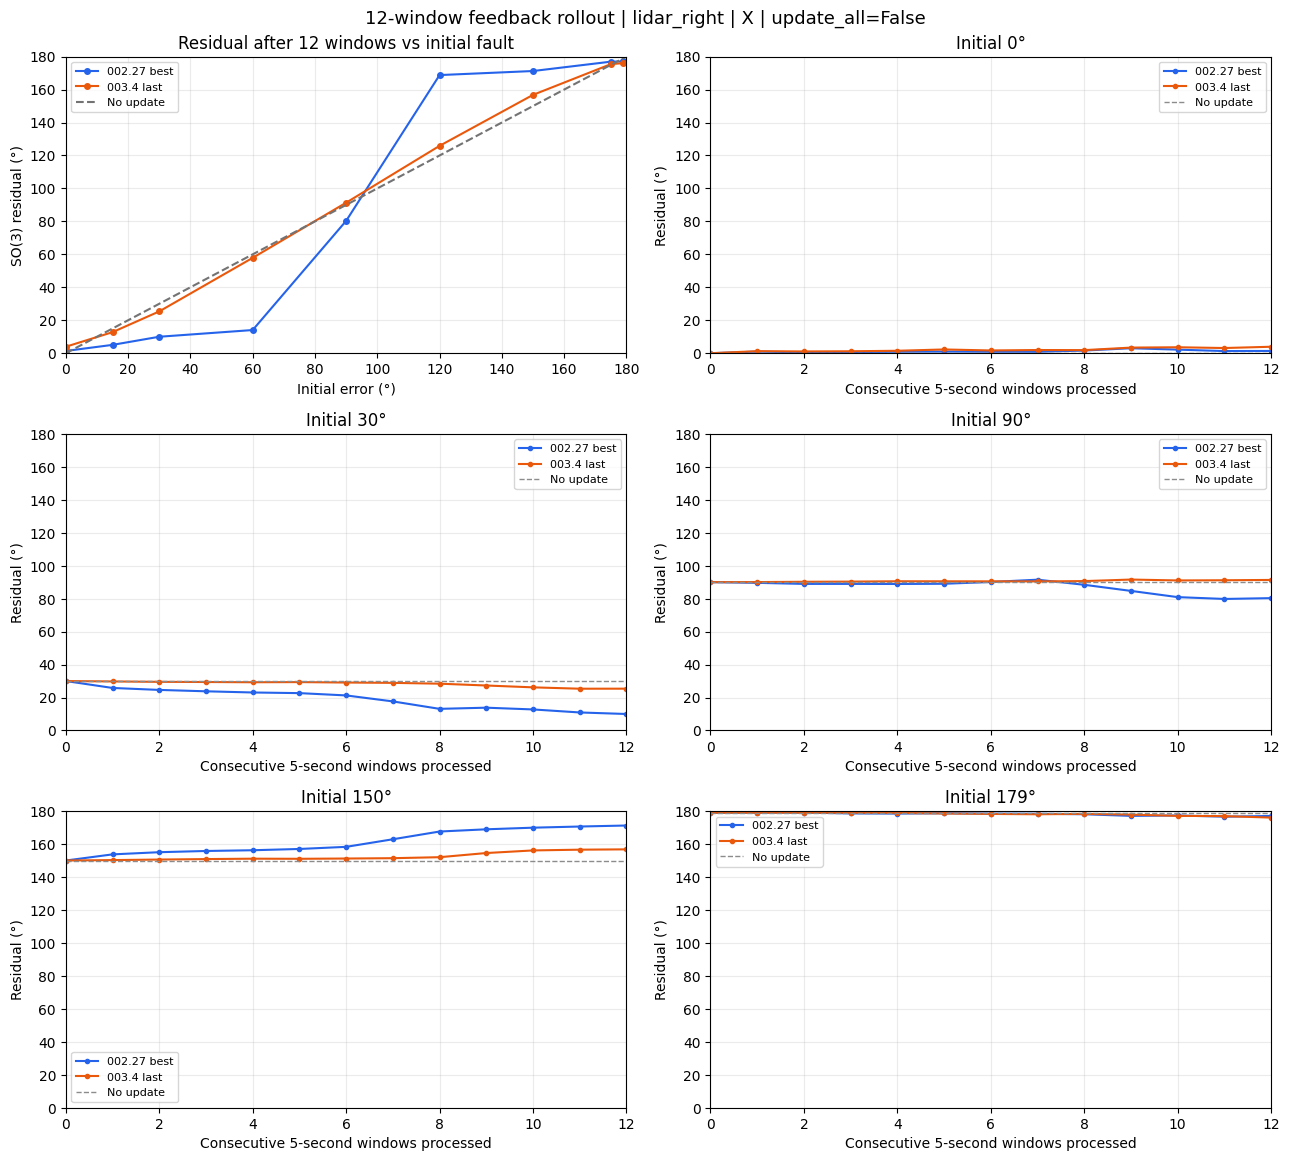

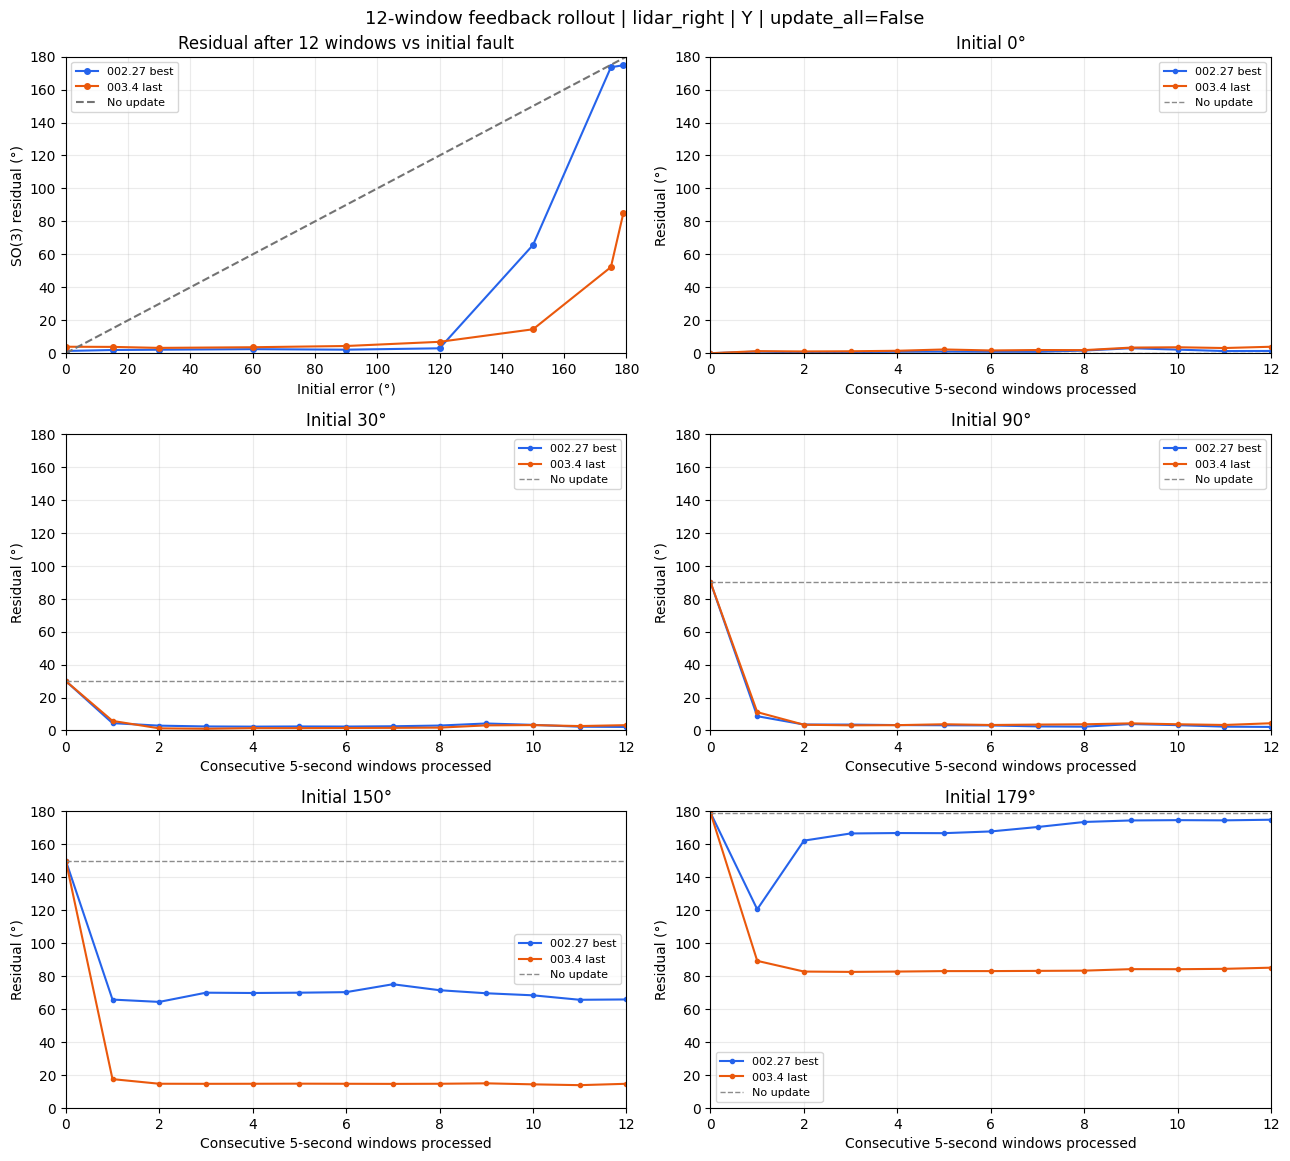

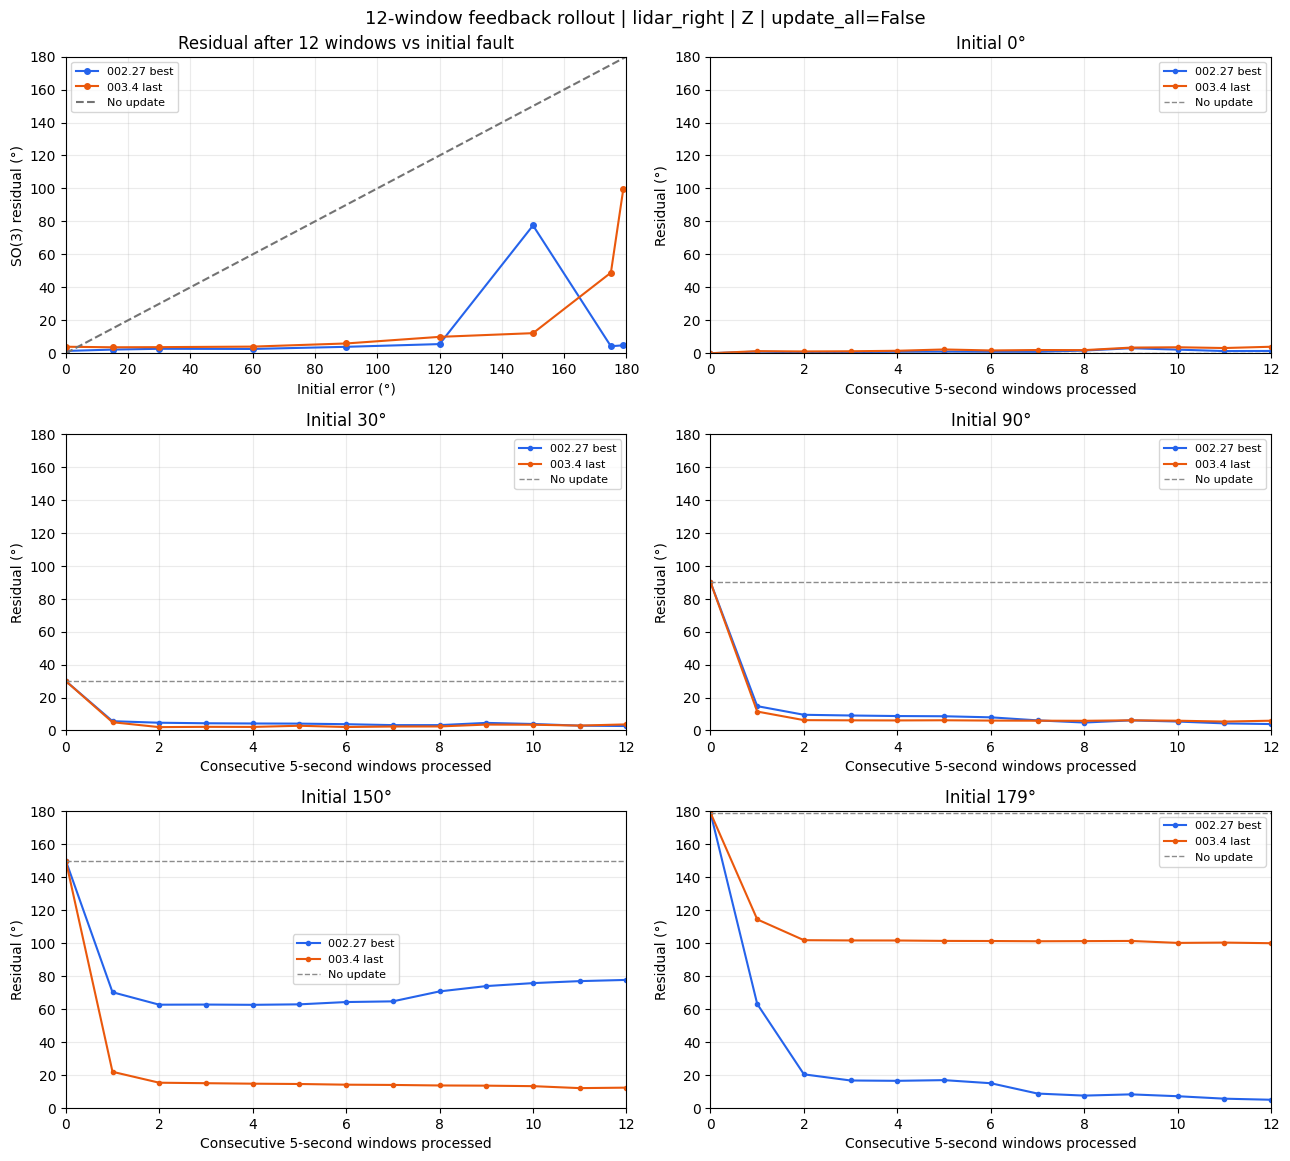

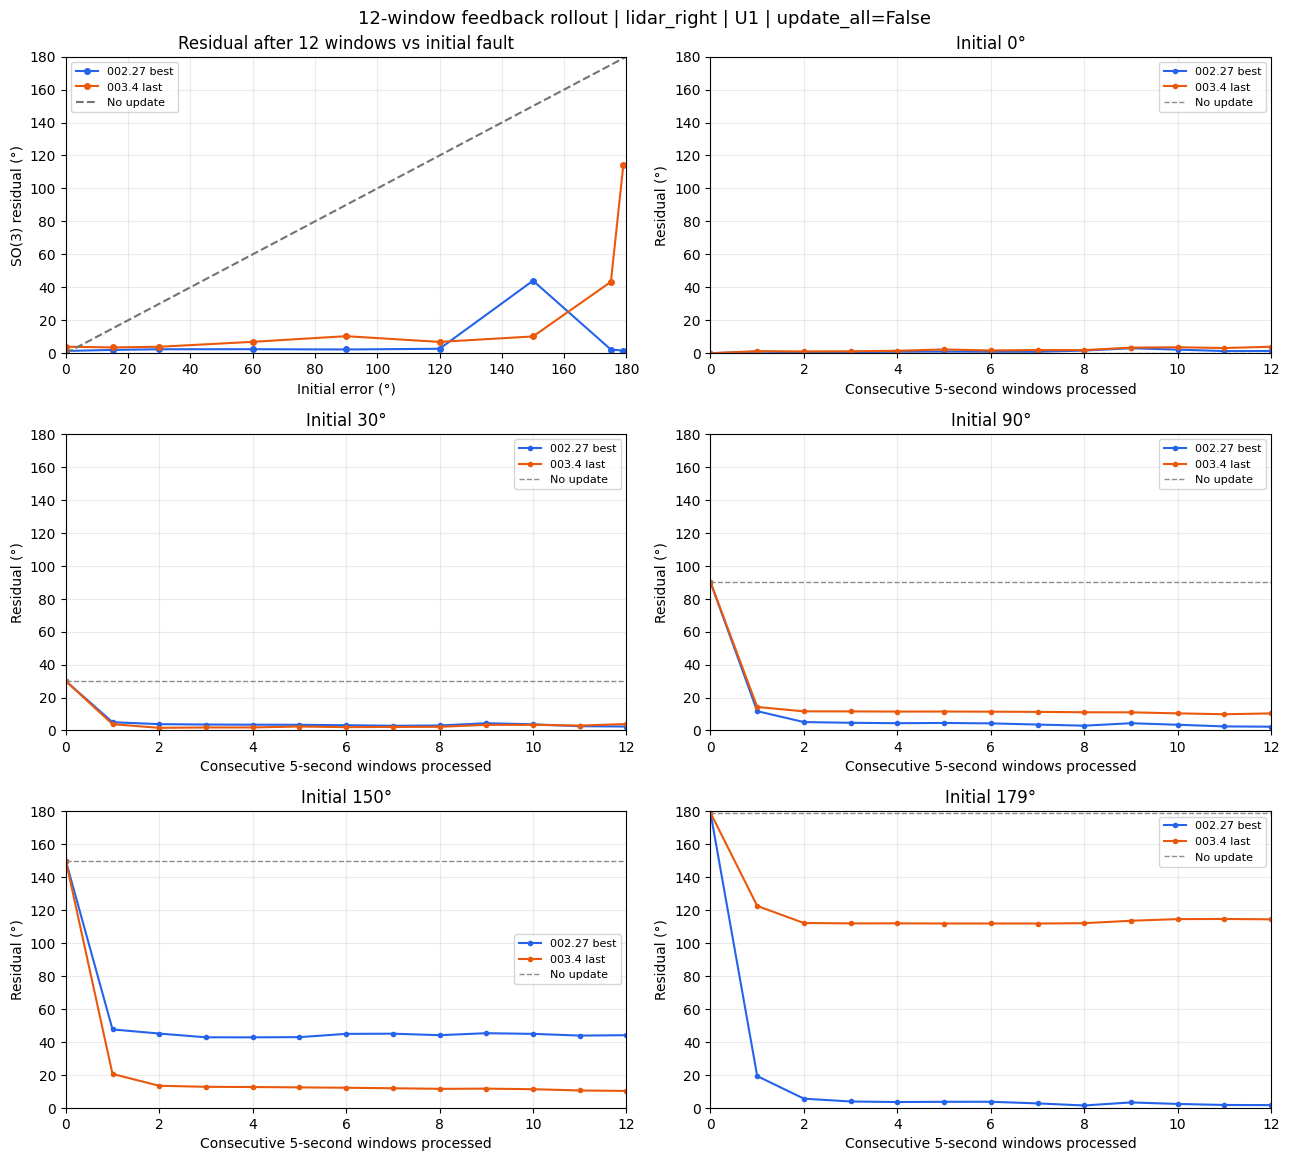

In [12]:
for sensor in FAULT_KEYS:
    for axis_name in AXIS_NAMES:
        fig,axs=plt.subplots(3,2,figsize=(13.0,11.8))
        final_ax=axs[0,0]
        for model_name in MODEL_ORDER:
            curve=rollout_summary[(rollout_summary.model==model_name)&(rollout_summary.sensor==sensor)&(rollout_summary.axis==axis_name)&(rollout_summary.step==ROLLOUT_NUM_WINDOWS)].sort_values('angle_deg')
            final_ax.plot(curve.angle_deg,curve.mean_residual_deg,'-o',label=model_name,color=COLORS[model_name],markersize=4)
        final_ax.plot([0,180],[0,180],'--',color='0.45',label='No update')
        final_ax.set(title='Residual after 12 windows vs initial fault',xlabel='Initial error (°)',ylabel='SO(3) residual (°)',xlim=(0,180),ylim=(0,180))
        final_ax.grid(alpha=.25)
        final_ax.legend(fontsize=8)
        for ax,angle in zip([axs[0,1],axs[1,0],axs[1,1],axs[2,0],axs[2,1]],ROLLOUT_TRACE_ANGLES):
            for model_name in MODEL_ORDER:
                curve=rollout_summary[(rollout_summary.model==model_name)&(rollout_summary.sensor==sensor)&(rollout_summary.axis==axis_name)&(rollout_summary.angle_deg==angle)].sort_values('step')
                ax.plot(curve.step,curve.mean_residual_deg,'-o',markersize=3,label=model_name,color=COLORS[model_name])
            ax.axhline(angle,color='0.55',linestyle='--',linewidth=1,label='No update')
            ax.set(title=f'Initial {angle:g}°',xlabel='Consecutive 5-second windows processed',ylabel='Residual (°)',xlim=(0,ROLLOUT_NUM_WINDOWS),ylim=(0,180))
            ax.grid(alpha=.25)
            ax.legend(fontsize=8)
        fig.suptitle(f'12-window feedback rollout | {sensor} | {axis_name} | update_all={ROLLOUT_UPDATE_ALL_KEYS}',fontsize=13)
        finish_figure(fig,f'rollout_{sensor}_{axis_name}.png')

## 11. Paired checkpoint differences and heatmaps

We compare matched rows *by physical example*, never by separately sampled faults. Define `delta = 003.4 residual − 002.27 residual`: **negative means 003.4 is better**, positive means 002.27 is better. Angle 0° measures false correction/drift.

One-step matched difference: 003.4 minus 002.27, negative means 003.4 better


,sensor,axis,angle_deg,cases,mean_delta_deg,median_delta_deg,win_34_pct,win_27_pct
0,imu,U1,0.0,24,1.04,0.86,16.67,83.33
2,imu,U1,30.0,48,11.60,14.16,14.58,85.42
4,imu,U1,90.0,48,43.01,51.42,6.25,93.75
6,imu,U1,150.0,48,-3.80,-3.77,58.33,41.67
8,imu,U1,179.0,48,-1.72,-3.18,60.42,39.58
9,imu,X,0.0,24,1.04,0.86,16.67,83.33
11,imu,X,30.0,48,3.93,3.63,10.42,89.58
13,imu,X,90.0,48,3.20,1.88,41.67,58.33
15,imu,X,150.0,48,-36.24,-34.11,100.00,0.00
17,imu,X,179.0,48,-46.53,-36.98,89.58,10.42


Final 12-window matched difference:


,sensor,axis,angle_deg,cases,mean_delta_deg,median_delta_deg,win_34_pct,win_27_pct
0,imu,U1,0.0,4,-0.48,-0.30,50.0,50.0
2,imu,U1,30.0,8,0.17,0.94,50.0,50.0
4,imu,U1,90.0,8,13.65,19.64,37.5,62.5
6,imu,U1,150.0,8,26.27,-0.03,50.0,50.0
8,imu,U1,179.0,8,26.98,-0.07,50.0,50.0
9,imu,X,0.0,4,-0.48,-0.30,50.0,50.0
11,imu,X,30.0,8,-0.63,-0.45,50.0,50.0
13,imu,X,90.0,8,-0.55,-0.07,50.0,50.0
15,imu,X,150.0,8,-0.58,-0.24,62.5,37.5
17,imu,X,179.0,8,-26.92,-36.78,50.0,50.0


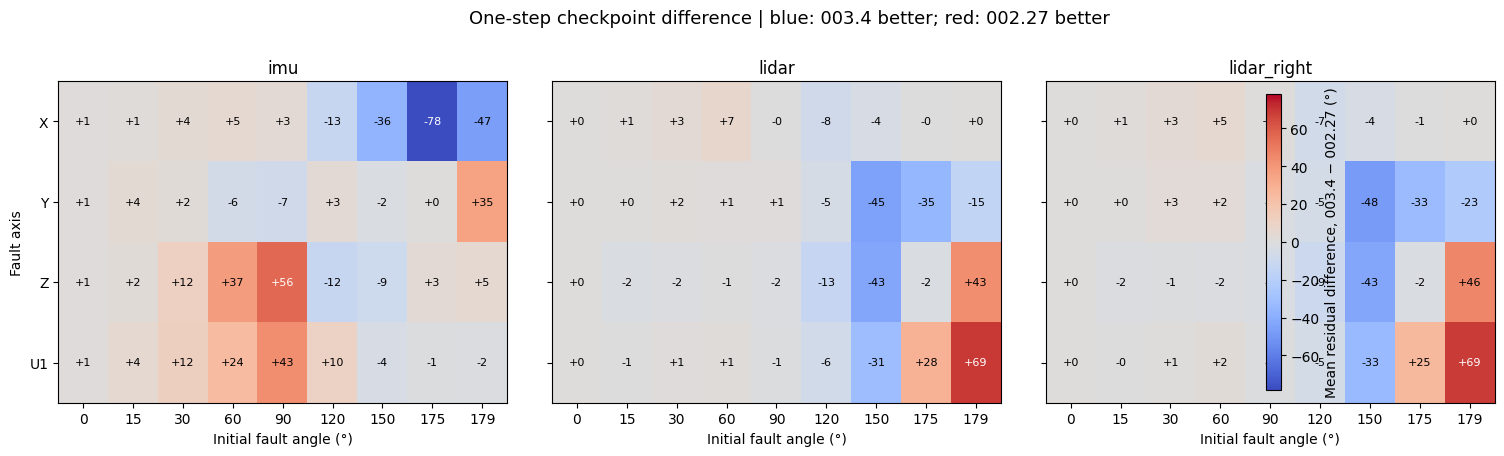

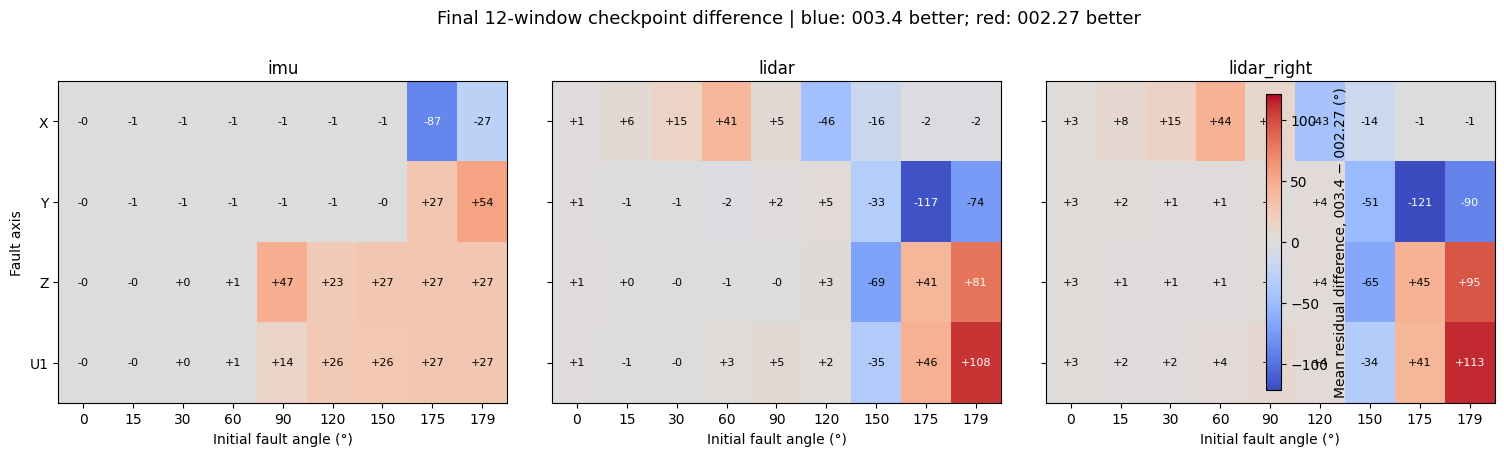

In [13]:
def matched_difference(df, case_columns):
    if df.duplicated(['model',*case_columns]).any():
        raise AssertionError('Duplicate rows for model and matched-case identity')
    pivot=df.pivot(index=case_columns,columns='model',values='residual_deg')
    if pivot.isna().any().any():
        raise AssertionError('Both models must be present on every case')
    diff=pivot.reset_index()
    diff['delta_34_minus_27_deg']=diff['003.4 last']-diff['002.27 best']
    diff['winner']=np.where(diff.delta_34_minus_27_deg < -1e-3,'003.4 last',np.where(diff.delta_34_minus_27_deg > 1e-3,'002.27 best','tie'))
    return diff

one_step_paired=matched_difference(one_step_df,['sequence','physical_index','sensor','axis','angle_deg','sign'])
rollout_paired=matched_difference(rollout_df,['sequence','start_index','sensor','axis','angle_deg','sign','step'])
one_step_paired.to_csv(OUTPUT_DIR/'one_step_paired_differences.csv',index=False)
rollout_paired.to_csv(OUTPUT_DIR/'rollout_paired_differences.csv',index=False)


def summarize_paired(df):
    return df.groupby(['sensor','axis','angle_deg'],as_index=False).agg(
        cases=('delta_34_minus_27_deg','size'),mean_delta_deg=('delta_34_minus_27_deg','mean'),
        median_delta_deg=('delta_34_minus_27_deg','median'),
        win_34_pct=('winner',lambda w:100*np.mean(w=='003.4 last')),
        win_27_pct=('winner',lambda w:100*np.mean(w=='002.27 best')))

one_step_delta_summary=summarize_paired(one_step_paired)
final_rollout_paired=rollout_paired[rollout_paired.step==ROLLOUT_NUM_WINDOWS]
rollout_delta_summary=summarize_paired(final_rollout_paired)
one_step_delta_summary.to_csv(OUTPUT_DIR/'one_step_paired_summary.csv',index=False)
rollout_delta_summary.to_csv(OUTPUT_DIR/'rollout_final_paired_summary.csv',index=False)

print('One-step matched difference: 003.4 minus 002.27, negative means 003.4 better')
display(one_step_delta_summary[one_step_delta_summary.angle_deg.isin((0.,30.,90.,150.,179.))].round(2))
print('Final 12-window matched difference:')
display(rollout_delta_summary[rollout_delta_summary.angle_deg.isin((0.,30.,90.,150.,179.))].round(2))


def plot_delta_heatmaps(summary, heading, filename):
    fig,axs=plt.subplots(1,3,figsize=(16.8,4.8),sharex=True,sharey=True)
    vlim=max(5.0,float(np.nanmax(np.abs(summary.mean_delta_deg))))
    for ax,sensor in zip(axs,FAULT_KEYS):
        data=summary[summary.sensor==sensor].pivot(index='axis',columns='angle_deg',values='mean_delta_deg').reindex(index=AXIS_NAMES,columns=ANGLES_DEG)
        image=ax.imshow(data.to_numpy(),cmap='coolwarm',vmin=-vlim,vmax=vlim,aspect='auto')
        ax.set(title=sensor,xticks=range(len(ANGLES_DEG)),xticklabels=[f'{a:g}' for a in ANGLES_DEG],yticks=range(len(AXIS_NAMES)),yticklabels=AXIS_NAMES)
        ax.set_xlabel('Initial fault angle (°)')
        if ax is axs[0]: ax.set_ylabel('Fault axis')
        for row in range(len(AXIS_NAMES)):
            for col in range(len(ANGLES_DEG)):
                value=data.iat[row,col]
                if np.isfinite(value):
                    ax.text(col,row,f'{value:+.0f}',ha='center',va='center',fontsize=8,color='black' if abs(value)<vlim*.65 else 'white')
    fig.colorbar(image,ax=axs.ravel().tolist(),label='Mean residual difference, 003.4 − 002.27 (°)',shrink=.80,pad=.015)
    fig.suptitle(heading+' | blue: 003.4 better; red: 002.27 better',fontsize=13)
    fig.subplots_adjust(left=.065,right=.92,top=.83,bottom=.16,wspace=.10)
    if SAVE_PLOTS: fig.savefig(OUTPUT_DIR/filename,dpi=PLOT_DPI,bbox_inches='tight')
    if SHOW_PLOTS: plt.show()
    else: plt.close(fig)

plot_delta_heatmaps(one_step_delta_summary,'One-step checkpoint difference','one_step_checkpoint_delta_heatmap.png')
plot_delta_heatmaps(rollout_delta_summary,'Final 12-window checkpoint difference','rollout_checkpoint_delta_heatmap.png')

## 12. Per-case checkpoint agreement and disagreement

The mean curve can hide a minority of difficult physical windows. These **matched-case scatter plots** compare the two checkpoints for the same sensor, initial axis, fault angle, sign, and physical example. Points below the diagonal favor `003.4`; points above favor `002.27`. Rollout examples share each physical sequence start across models.

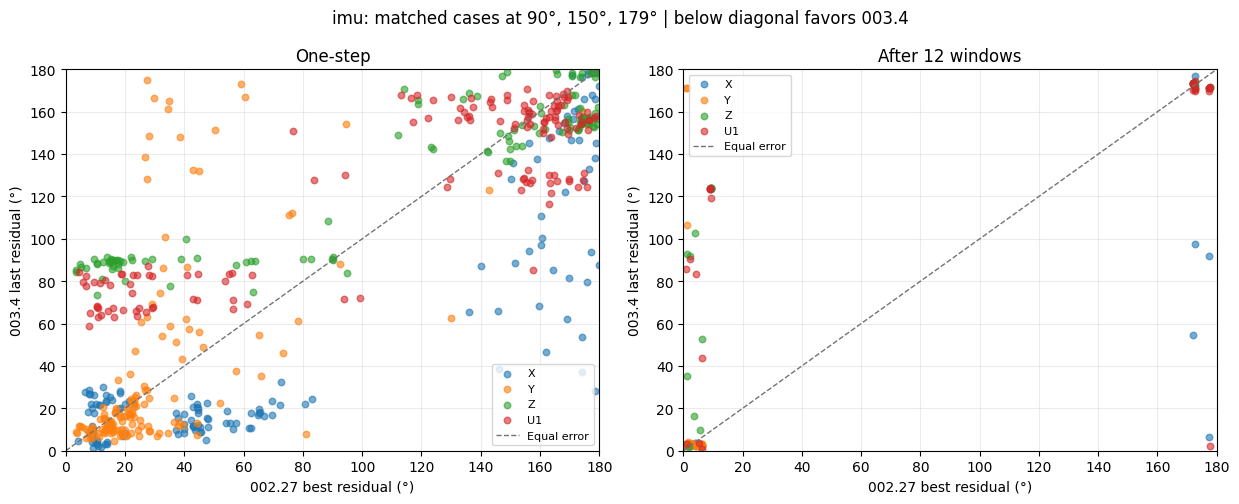

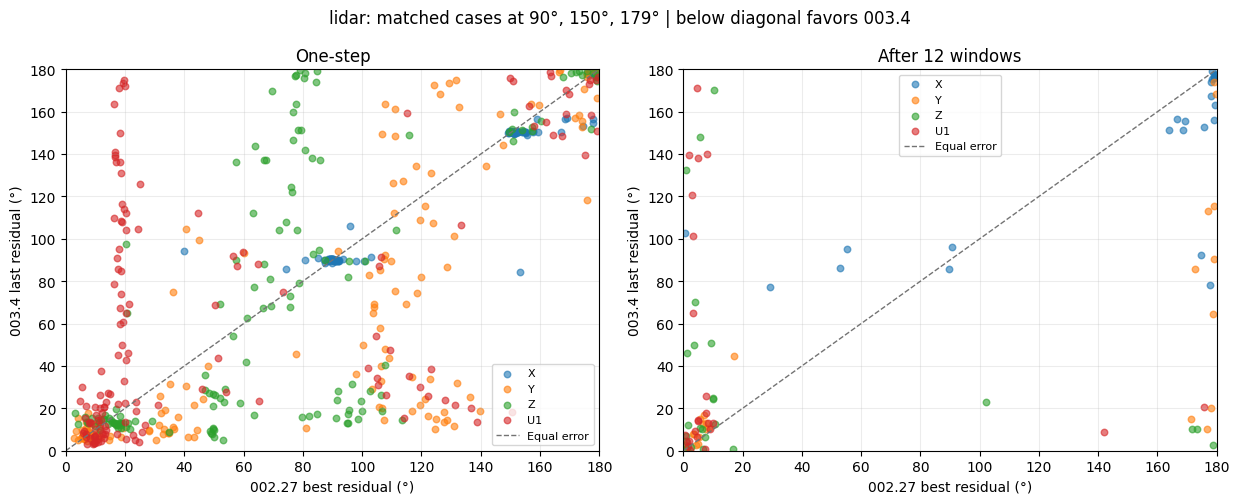

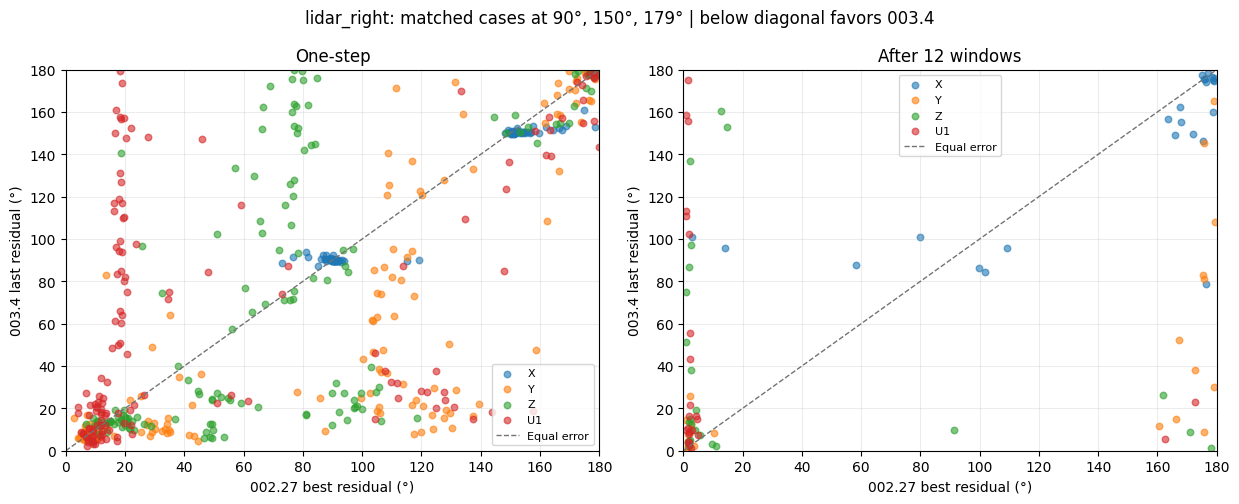

In [14]:
# Paired per-case plots focus on challenging 90°/150°/179° faults; each dot is a matched case.
for sensor in FAULT_KEYS:
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.1))
    for ax, source, caption in (
        (axes[0], one_step_paired, 'One-step'),
        (axes[1], final_rollout_paired, 'After 12 windows'),
    ):
        data = source[(source.sensor == sensor) & (source.angle_deg.isin((90., 150., 179.)))]
        for axis_name in AXIS_NAMES:
            points = data[data.axis == axis_name]
            ax.scatter(points['002.27 best'], points['003.4 last'], s=22, alpha=.60, label=axis_name)
        ax.plot([0, 180], [0, 180], '--', color='0.45', linewidth=1, label='Equal error')
        ax.set(title=caption, xlabel='002.27 best residual (°)', ylabel='003.4 last residual (°)', xlim=(0,180), ylim=(0,180))
        ax.grid(alpha=.23)
        ax.legend(fontsize=8)
    fig.suptitle(f'{sensor}: matched cases at 90°, 150°, 179° | below diagonal favors 003.4', fontsize=12)
    finish_figure(fig, f'paired_scatter_{sensor}.png')

## 13. Final scorecard: zero-error drift, mean/median/p90 residual and success at 10°

In [15]:
def scorecard_for(df, label):
    nonzero=df[df.angle_deg>0]
    grouped=nonzero.groupby(['model','sensor'],as_index=False).agg(
        n=('residual_deg','size'),mean_initial_deg=('angle_deg','mean'),mean_residual_deg=('residual_deg','mean'),
        median_residual_deg=('residual_deg','median'),p90_residual_deg=('residual_deg',lambda x:np.percentile(x,90)),
        improved_pct=('improved',lambda x:100*x.mean()),success_10deg_pct=('success_10deg',lambda x:100*x.mean()))
    zeros=df[df.angle_deg==0].groupby(['model','sensor'],as_index=False).agg(zero_drift_deg=('residual_deg','mean'))
    grouped=grouped.merge(zeros,on=['model','sensor'],how='left')
    grouped.insert(0,'evaluation',label)
    return grouped

summary_one=scorecard_for(one_step_df,'one_step')
summary_final=scorecard_for(rollout_df[rollout_df.step==ROLLOUT_NUM_WINDOWS],'after_12_windows')
scorecard=pd.concat([summary_one,summary_final],ignore_index=True)
scorecard.to_csv(OUTPUT_DIR/'checkpoint_scorecard.csv',index=False)
display(scorecard.round(2))

print('\nSelected 30°/90°/150°/179° final rollout residuals by sensor and axis:')
final_table=rollout_summary[(rollout_summary.step==ROLLOUT_NUM_WINDOWS)&(rollout_summary.angle_deg.isin((30.,90.,150.,179.)))]
display(final_table.pivot_table(index=['sensor','axis','angle_deg'],columns='model',values='mean_residual_deg').round(1))

config_summary={
    'checkpoints':{key:str(val) for key,val in CHECKPOINTS.items()},'split':EVAL_SPLIT,
    'sequences':EVAL_SEQUENCES,'angles_deg':ANGLES_DEG,'axis_names':AXIS_NAMES,
    'axis_vectors':{key:val.cpu().numpy().tolist() for key,val in AXES.items()},
    'one_step_windows_per_sequence':ONE_STEP_WINDOWS_PER_SEQUENCE,
    'rollout_windows':ROLLOUT_NUM_WINDOWS,'rollout_starts_per_sequence':ROLLOUT_STARTS_PER_SEQUENCE,
    'rollout_update_all_keys':ROLLOUT_UPDATE_ALL_KEYS,
    'true_rotation_max_deg':TRUE_CALIBRATION_ROTATION_MAX_DEG,'true_time_offset_max_s':TRUE_CALIBRATION_TAU_MAX_S,
    'one_step_seed':ONE_STEP_PHYSICAL_SEED,'rollout_seed':ROLLOUT_PHYSICAL_SEED,
}
(OUTPUT_DIR/'evaluation_config.json').write_text(json.dumps(config_summary,indent=2),encoding='utf-8')
print('\nSaved all results under:',OUTPUT_DIR)
print('No optimizer was constructed and neither checkpoint was modified.')

,evaluation,model,sensor,n,mean_initial_deg,mean_residual_deg,median_residual_deg,p90_residual_deg,improved_pct,success_10deg_pct,zero_drift_deg
0,one_step,002.27 best,imu,1536,102.38,60.04,21.35,170.46,88.35,31.58,0.59
1,one_step,002.27 best,lidar,1536,102.38,60.41,28.12,170.63,83.07,22.53,1.24
2,one_step,002.27 best,lidar_right,1536,102.38,60.68,27.09,172.77,82.16,23.83,1.26
3,one_step,003.4 last,imu,1536,102.38,61.63,24.89,161.26,88.28,19.27,1.63
4,one_step,003.4 last,lidar,1536,102.38,58.59,26.24,173.41,81.12,27.47,1.56
5,one_step,003.4 last,lidar_right,1536,102.38,58.65,24.88,173.52,80.79,27.34,1.57
6,after_12_windows,002.27 best,imu,256,102.38,42.40,4.88,172.58,89.06,76.95,2.94
7,after_12_windows,002.27 best,lidar,256,102.38,44.94,7.41,178.27,82.42,66.80,4.30
8,after_12_windows,002.27 best,lidar_right,256,102.38,43.51,2.92,175.85,83.98,69.53,1.38
9,after_12_windows,003.4 last,imu,256,102.38,49.69,3.18,171.60,89.84,65.23,2.46



Selected 30°/90°/150°/179° final rollout residuals by sensor and axis:


model                       002.27 best  003.4 last
sensor      axis angle_deg                         
imu         U1   30.0               2.9         3.0
                 90.0              25.5        39.2
                 150.0            132.8       159.1
                 179.0            132.8       159.7
            X    30.0               3.3         2.7
                 90.0               3.3         2.8
                 150.0              3.3         2.7
                 179.0            132.9       105.9
            Y    30.0               3.2         2.5
                 90.0               3.2         2.6
                 150.0              3.3         3.1
                 179.0              3.5        58.0
            Z    30.0               3.0         3.1
                 90.0               3.3        50.5
                 150.0            132.8       160.2
                 179.0            132.8       160.3
lidar       U1   30.0               5.1         5.0
                 90.0               4.5         9.4
                 150.0             43.9         9.0
                 179.0              4.5       112.7
            X    30.0               9.3        24.1
                 90.0              83.9        89.3
                 150.0            172.5       156.8
                 179.0            178.9       176.7
            Y    30.0               5.5         4.4
                 90.0               4.4         5.9
                 150.0             49.6        16.6
                 179.0            177.9       104.0
            Z    30.0               4.7         4.7
                 90.0               5.8         5.7
                 150.0             81.2        11.9
                 179.0              5.7        86.6
lidar_right U1   30.0               2.4         3.9
                 90.0               2.3        10.3
                 150.0             44.0        10.2
                 179.0              1.6       114.3
            X    30.0              10.0        25.4
                 90.0              80.3        91.4
                 150.0            171.2       156.8
                 179.0            177.1       176.1
            Y    30.0               2.1         3.2
                 90.0               2.2         4.4
                 150.0             65.7        14.5
                 179.0            174.8        85.0
            Z    30.0               2.7         3.7
                 90.0               3.9         5.9
                 150.0             77.6        12.2
                 179.0              4.8        99.8


Saved all results under: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/checkpoint_comparison_00227_best_vs_0034_last/validation
No optimizer was constructed and neither checkpoint was modified.
